# Лабораторная работа 3. Регрессионный анализ

**Выполнил:** Моисеев Г. В., группа 4414

**Вариант 16.** В файле `regression.xlsx` 10 вариантов (листы `var1`–`var10`), поэтому номер взят по кругу: 16 → 6, лист `var6`.

**Цель работы:** изучение алгоритмов регрессии на практике.

Оба файла с данными читаются из папки `data`, если ноутбук запущен локально. В Colab такой папки нет, и тогда файлы скачиваются из репозитория на GitHub.

`RANDOM_STATE` фиксирует разбиение выборок и построение дерева, чтобы при каждом запуске получались одни и те же числа.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor

%config InlineBackend.figure_format = 'retina'
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
DATA_DIR = Path('data')
DATA_URL = 'https://raw.githubusercontent.com/Echways/IDA/main/lab-3/data/'


def data_source(name):
    """Файл из папки data, а если её нет — тот же файл из репозитория на GitHub."""
    path = DATA_DIR / name
    return path if path.exists() else DATA_URL + name

## Часть 1. Простая линейная регрессия

### 1.1. Загрузка данных и описательные статистики

In [2]:
points = pd.read_excel(data_source('regression.xlsx'), sheet_name='var6')
points.head()

,x1,x2,y
0,-1.146666,-0.688365,-1.387058
1,-0.060865,1.590076,1.879463
2,0.910263,-1.847089,0.455931
3,-0.293059,-1.514869,-2.048716
4,0.096293,-0.193451,0.002519


In [3]:
points.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      1000 non-null   float64
 1   x2      1000 non-null   float64
 2   y       1000 non-null   float64
dtypes: float64(3)
memory usage: 23.6 KB


В таблице 1000 строк и 3 столбца: признаки `x1`, `x2` и целевая переменная `y`. Все столбцы имеют тип `float64`, пропусков нет.

In [4]:
points.describe()

,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,0.000004,0.000018,-0.007679
std,1.155243,1.155356,1.925932
min,-1.999033,-1.996413,-5.667686
25%,-0.999680,-0.997221,-1.377376
50%,-0.000644,0.000012,-0.025591
75%,0.998839,0.999964,1.345011
max,1.996395,1.997690,5.520120


- `x1` и `x2` лежат в пределах от −2 до 2, среднее и медиана равны нулю, квартили −1 и 1. Значения распределены равномерно: стандартное отклонение 1.155 совпадает с $4 / \sqrt{12}$ для равномерного распределения на отрезке длиной 4.
- `y` меняется от −5.67 до 5.52, среднее −0.008, стандартное отклонение 1.93.

Масштаб признаков одинаковый, поэтому стандартизация в этой части не нужна.

Парные коэффициенты корреляции Пирсона:

In [5]:
points.corr(method='pearson')

,x1,x2,y
x1,1.000000,-0.003132,0.770348
x2,-0.003132,1.000000,0.505821
y,0.770348,0.505821,1.000000


Предварительное заключение:

- `x1` и `y` — 0.77, связь прямая и сильная: с ростом `x1` растёт `y`.
- `x2` и `y` — 0.51, связь прямая, средней силы.
- `x1` и `x2` — −0.003, признаки между собой не связаны.

Линейная модель по `x1` должна получиться точнее, чем по `x2`. Коэффициент Пирсона оценивает только линейную связь, поэтому 0.51 у `x2` ещё не говорит, что связь слабая: она может быть нелинейной. Это проверяется на графиках ниже.

### 1.2. Разделение выборки и обучение моделей

Таблица делится на обучающую и тестовую выборки в соотношении 3 к 1 (`test_size=0.25`). Разбиение одно для обеих моделей: тогда модели по `x1` и по `x2` проверяются на одних и тех же 250 строках, и их метрики можно сравнивать напрямую.

Обучаются две модели парной линейной регрессии $y = ax + b$: первая по `x1`, вторая по `x2`.

In [6]:
train, test = train_test_split(points, test_size=0.25, random_state=RANDOM_STATE)
print(f'Обучающая выборка: {len(train)} строк, тестовая: {len(test)} строк')

simple_models = {}
for feature in ['x1', 'x2']:
    simple_models[feature] = LinearRegression().fit(train[[feature]], train['y'])

Обучающая выборка: 750 строк, тестовая: 250 строк


### 1.3. Предсказание

Предсказания обеих моделей на тестовой выборке собраны в один датафрейм рядом с истинными значениями `y`.

In [7]:
predictions = pd.DataFrame({'Actual': test['y']})
for feature, model in simple_models.items():
    predictions[f'Predicted ({feature})'] = model.predict(test[[feature]])

predictions.head(10)

,Actual,Predicted (x1),Predicted (x2)
521,0.897102,2.445628,-1.014775
737,1.517751,1.155928,-1.327183
740,-1.115664,-1.184611,-0.830492
660,0.897899,0.681463,0.026153
411,-4.131951,-2.364999,-1.651730
678,-3.041178,-1.135106,-1.331875
626,-0.312387,-0.469747,0.365710
513,1.532252,0.087594,1.099324
859,-3.766478,-2.514750,-1.208523
136,4.138962,2.490545,1.469590


Уже по первым строкам видно, что предсказания по `x2` лежат ближе к нулю, чем истинные значения: при `y` = −4.13 модель по `x1` даёт −2.36, а модель по `x2` — только −1.65.

### 1.4. Метрики качества

- **MSE** — средний квадрат ошибки. Сильно штрафует большие ошибки, измеряется в квадратах единиц `y`.
- **MAE** — средняя абсолютная ошибка: на сколько в среднем предсказание отличается от истинного значения.
- **RMSE** — корень из MSE, измеряется в тех же единицах, что и `y`.
- **R2** — доля дисперсии `y`, которую объясняет модель: 1 у идеальной модели, 0 у модели, которая всегда предсказывает среднее.

In [8]:
def regression_metrics(y_true, y_pred):
    """MSE, MAE, RMSE и R2 для одного набора предсказаний."""
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mse),
            'R2': r2_score(y_true, y_pred)}


pd.DataFrame({f'y по {feature}': regression_metrics(predictions['Actual'],
                                                    predictions[f'Predicted ({feature})'])
              for feature in simple_models}).T

,MSE,MAE,RMSE,R2
y по x1,1.478619,0.926510,1.215985,0.557549
y по x2,2.673647,1.358305,1.635129,0.199958


- Модель по `x1` объясняет 56 % дисперсии `y` на тестовой выборке, модель по `x2` — только 20 %.
- Средняя абсолютная ошибка модели по `x1` — 0.93, по `x2` — 1.36, то есть в полтора раза больше.
- RMSE больше MAE у обеих моделей (1.22 против 0.93 и 1.64 против 1.36): в данных есть отдельные большие ошибки, которые возведение в квадрат усиливает.
- Стандартное отклонение `y` в тестовой выборке равно 1.83. RMSE модели по `x2` (1.64) близко к этому числу — такая модель немногим лучше предсказания средним.

Ни одна из моделей не точна: `y` зависит от обоих признаков, а каждая модель видит только один.

### 1.5. Коэффициенты a и b

In [9]:
pd.DataFrame({'a': [model.coef_[0] for model in simple_models.values()],
              'b': [model.intercept_ for model in simple_models.values()]},
             index=[f'y = a * {feature} + b' for feature in simple_models])

,a,b
y = a * x1 + b,1.308185,0.027343
y = a * x2 + b,0.880624,-0.024125


- `y = 1.308 * x1 + 0.027`: при увеличении `x1` на единицу `y` в среднем растёт на 1.31.
- `y = 0.881 * x2 − 0.024`: при увеличении `x2` на единицу `y` в среднем растёт на 0.88.

Свободный член `b` у обеих моделей близок к нулю: средние значения признаков и `y` равны нулю, и прямые проходят почти через начало координат.

### 1.6. Визуализация регрессии

Точки — все 1000 наблюдений, красная линия — найденная прямая регрессии.

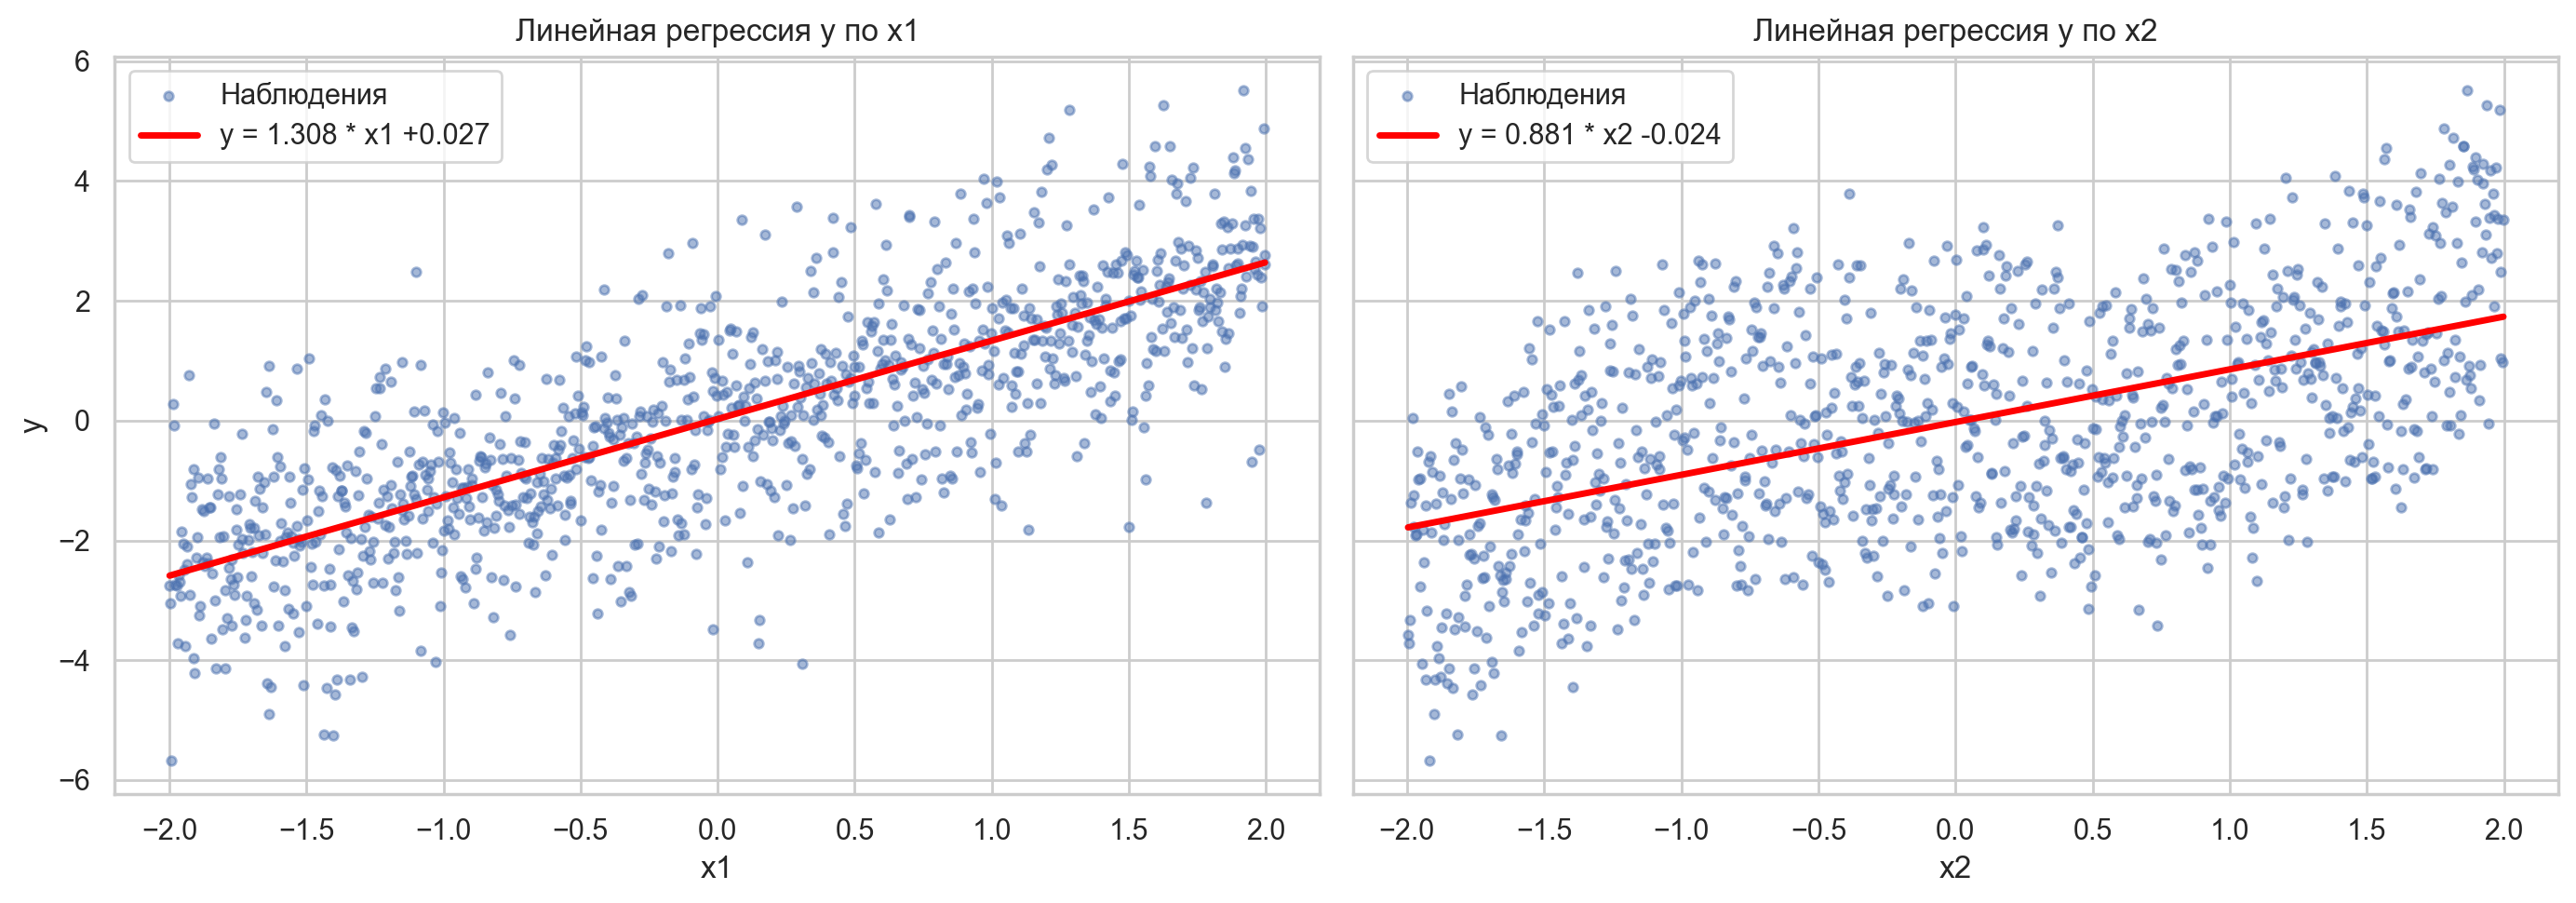

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (feature, model) in zip(axes, simple_models.items()):
    a, b = model.coef_[0], model.intercept_
    line_x = np.array([points[feature].min(), points[feature].max()])
    ax.scatter(points[feature], points['y'], s=12, alpha=0.5, label='Наблюдения')
    ax.plot(line_x, a * line_x + b, color='red', linewidth=2.5,
            label=f'y = {a:.3f} * {feature} {b:+.3f}')
    ax.set(xlabel=feature, title=f'Линейная регрессия y по {feature}')
    ax.legend()

axes[0].set_ylabel('y')
fig.tight_layout()
plt.show()

- `x1`: облако точек вытянуто вдоль прямой, ширина облака примерно одинакова на всём отрезке. Зависимость линейная, прямая описывает её правильно, а разброс вокруг прямой — это влияние `x2` и шума.
- `x2`: облако изогнуто. В середине, от −1 до 1, `y` почти не меняется, а у краёв меняется быстро: слева точки уходят ниже прямой, справа — выше. Прямая эту форму не повторяет.

### 1.7. Разница предсказанного и истинного значения

Для каждой точки тестовой выборки отложена разница между предсказанным и истинным значением `y`. Точка выше красной линии — модель завысила значение, ниже — занизила.

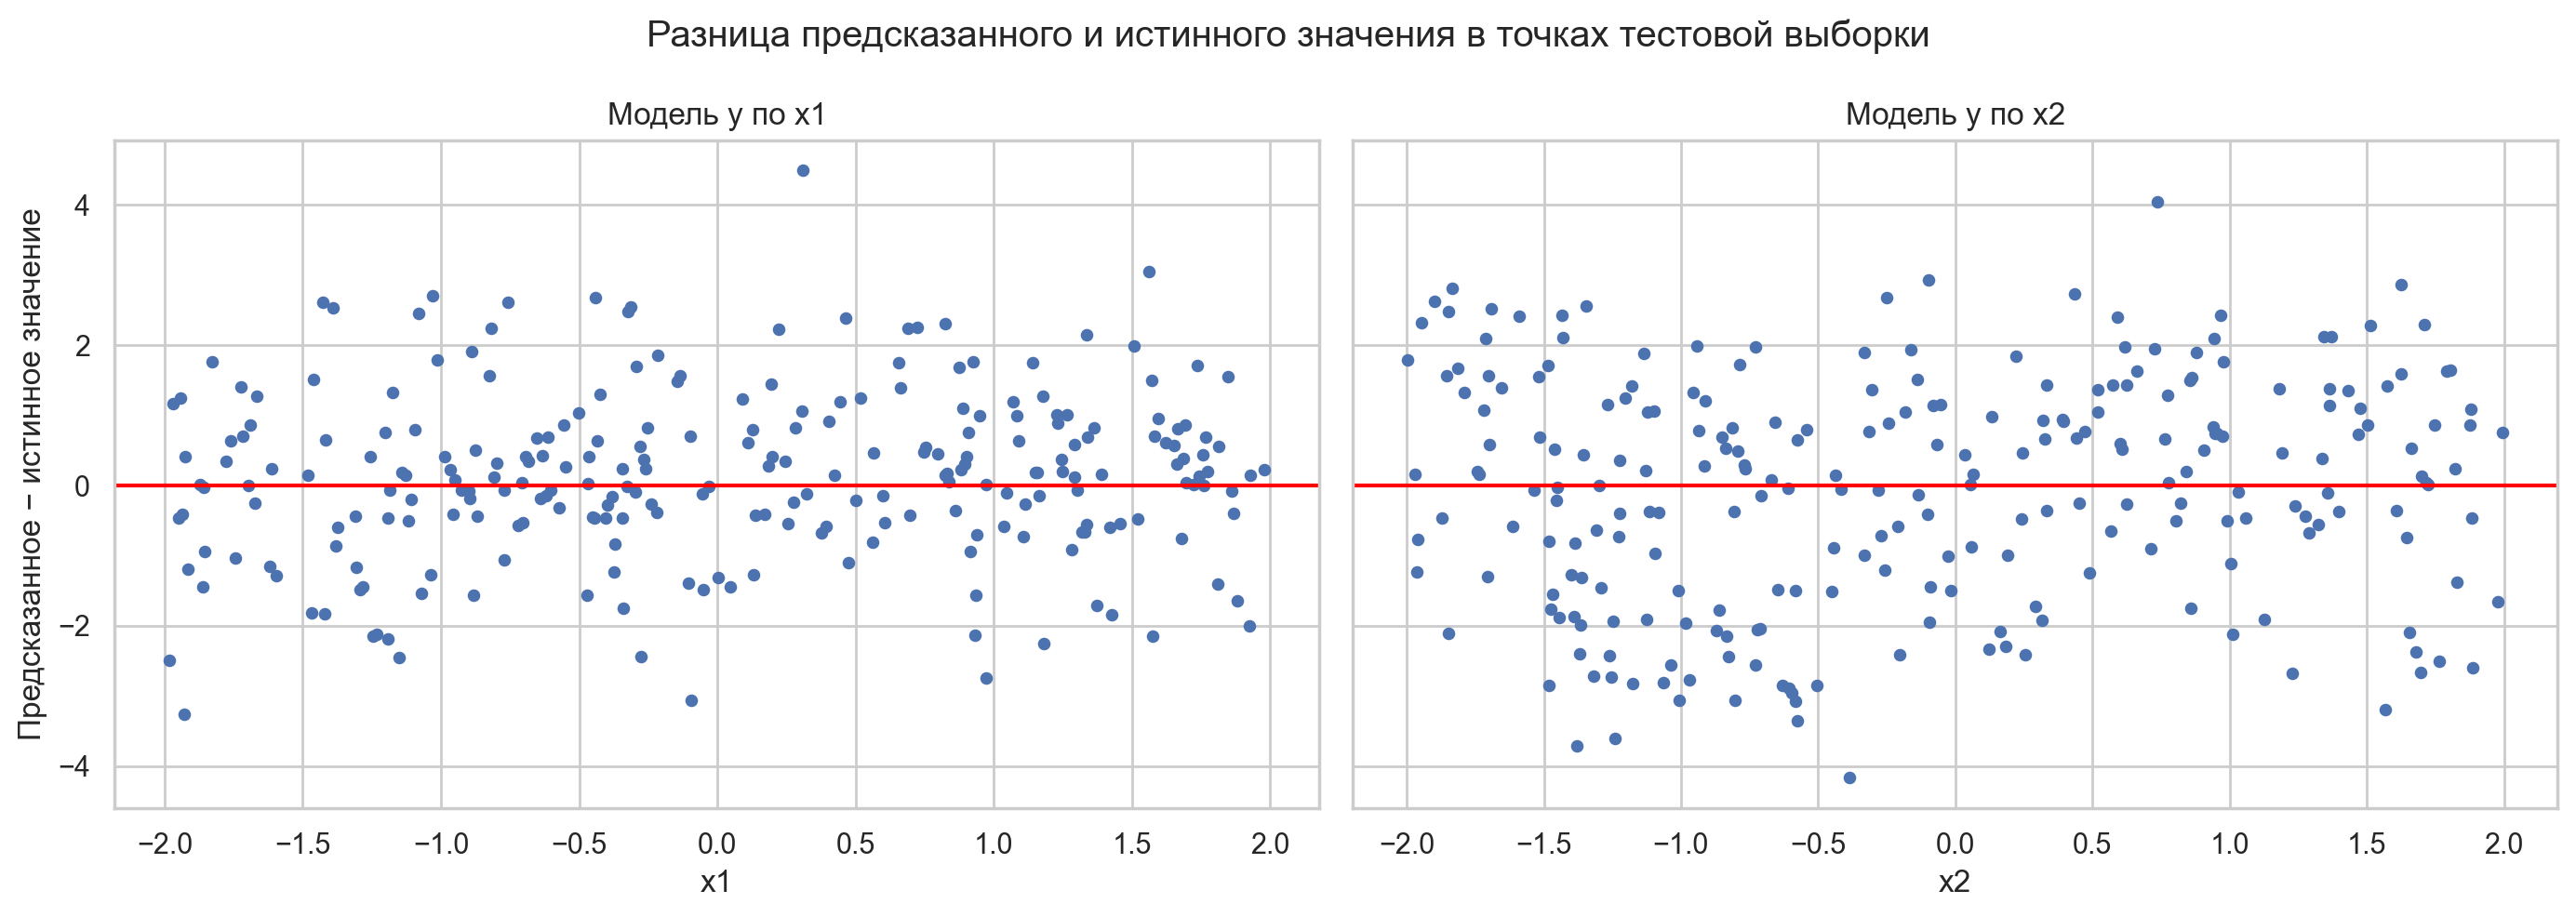

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, feature in zip(axes, simple_models):
    difference = predictions[f'Predicted ({feature})'] - predictions['Actual']
    ax.scatter(test[feature], difference, s=15)
    ax.axhline(0, color='red')
    ax.set(xlabel=feature, title=f'Модель y по {feature}')

axes[0].set_ylabel('Предсказанное − истинное значение')
fig.suptitle('Разница предсказанного и истинного значения в точках тестовой выборки')
fig.tight_layout()
plt.show()

- `x1`: точки разбросаны вокруг нуля без какой-либо формы, от −3.3 до 4.5. У 63 % точек ошибка меньше 1 по модулю. Ошибка не зависит от `x1`, значит прямая описывает связь полностью.
- `x2`: разброс шире, от −4.2 до 4.1, ошибка меньше 1 только у 42 % точек. В ошибках видна волна: при `x2` от −2 до −1.5 модель в среднем завышает `y` на 0.91, от −1.5 до −0.5 — занижает на 0.79, от 0.5 до 1.5 — снова завышает на 0.58. Ошибка зависит от `x2`, а это признак нелинейной связи, которую прямая пропускает.

### 1.8. Предсказанные и истинные значения

Красная линия — истинные значения, то есть идеальное совпадение прогноза с фактом. Синие точки — предсказания. Чем ближе точки к линии, тем точнее модель.

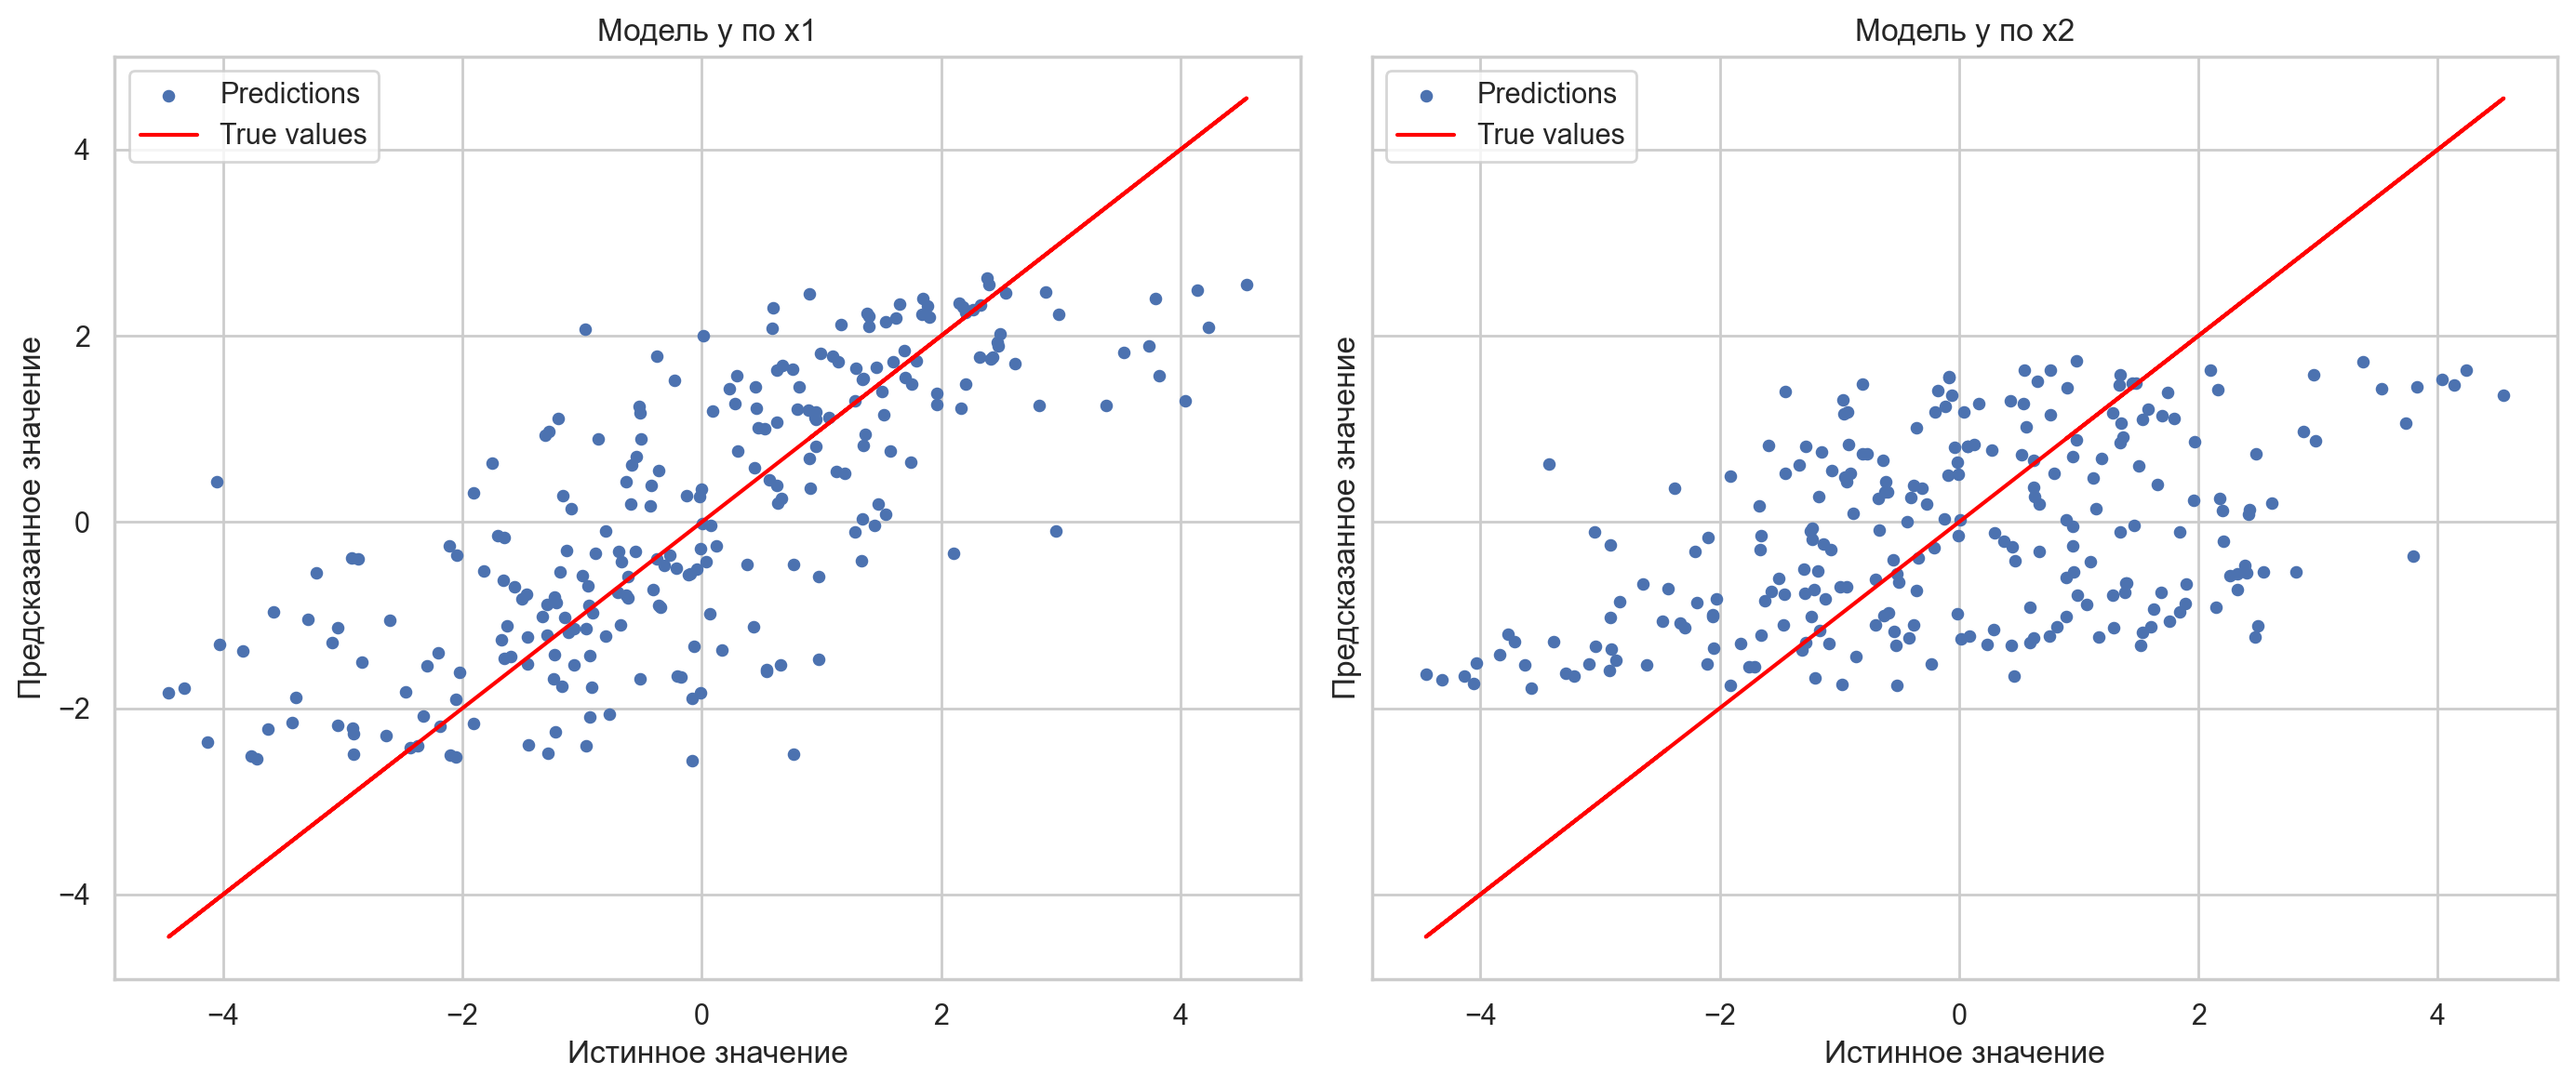

In [12]:
def plot_predictions(ax, y_true, y_pred, title):
    """Предсказания против истинных значений; красная линия — идеальное совпадение."""
    ax.scatter(y_true, y_pred, s=15, label='Predictions')
    ax.plot(y_true, y_true, color='red', label='True values')
    ax.set(xlabel='Истинное значение', ylabel='Предсказанное значение', title=title)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, feature in zip(axes, simple_models):
    plot_predictions(ax, predictions['Actual'], predictions[f'Predicted ({feature})'],
                     f'Модель y по {feature}')

fig.tight_layout()
plt.show()

- `x1`: точки идут вдоль красной линии, но облако наклонено слабее. Предсказания лежат в пределах от −2.6 до 2.6, а истинные значения — от −4.5 до 4.6. Крайние значения модель недотягивает: большие `y` занижает, малые завышает.
- `x2`: облако почти горизонтальное, предсказания не выходят за пределы от −1.8 до 1.7. Модель слабо реагирует на изменение `y`.

### 1.9. Выводы по части 1

- Связь `x1` и `y` линейная и сильная (корреляция 0.77). Парная регрессия `y = 1.308 * x1 + 0.027` даёт R2 = 0.56 и MAE = 0.93, ошибки не зависят от `x1`.
- Связь `x2` и `y` слабее (корреляция 0.51) и нелинейна. Парная регрессия `y = 0.881 * x2 − 0.024` даёт R2 = 0.20 и MAE = 1.36, а в её ошибках видна волна.
- Для прогноза `y` по одному признаку лучше подходит `x1`. Для `x2` прямая — слишком простая модель, и её стоит заменить полиномом.

## Часть 2. Полиномиальная регрессия

### 2.1. Выбор признака

Полиномиальную регрессию целесообразно применять к `x2`:

- на диаграмме рассеяния из раздела 1.6 облако `x2` изогнуто, а облако `x1` вытянуто вдоль прямой;
- в ошибках линейной модели по `x2` есть волна (раздел 1.7), в ошибках модели по `x1` её нет.

Для проверки на каждом признаке обучены полиномы степени 1 и степени 3. Функция `fit_polynomial` собирает модель из двух шагов: `PolynomialFeatures` добавляет к признаку его степени, затем на них обучается `LinearRegression`. Столбец из единиц отключён (`include_bias=False`), так как свободный член линейная регрессия подбирает сама. Функция `train_test_scores` считает R2 и MAE на обучающей и тестовой выборках.

In [13]:
def fit_polynomial(degree, feature='x2'):
    """Полиномиальная регрессия y по одному признаку: PolynomialFeatures, затем LinearRegression."""
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                          LinearRegression())
    return model.fit(train[[feature]], train['y'])


def train_test_scores(model, X_train, X_test, y_train, y_test):
    """R2 и MAE модели на обучающей и тестовой выборках."""
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)
    return {'R2 train': r2_score(y_train, pred_train),
            'R2 test': r2_score(y_test, pred_test),
            'MAE train': mean_absolute_error(y_train, pred_train),
            'MAE test': mean_absolute_error(y_test, pred_test)}


feature_check = {}
for feature in ['x1', 'x2']:
    for degree in [1, 3]:
        model = fit_polynomial(degree, feature)
        feature_check[(feature, degree)] = train_test_scores(
            model, train[[feature]], test[[feature]], train['y'], test['y'])

pd.DataFrame(feature_check).T.rename_axis(['Признак', 'Степень полинома'])

R2 train   R2 test  MAE train  MAE test
Признак Степень полинома                                         
x1      1                 0.602957  0.557549   0.927653  0.926510
        3                 0.603770  0.560842   0.926504  0.928903
x2      1                 0.270955  0.199958   1.405642  1.358305
        3                 0.333691  0.273466   1.354580  1.314823

Для `x1` переход к степени 3 ничего не даёт: R2 на тесте меняется с 0.558 до 0.561. Для `x2` R2 на тесте растёт с 0.200 до 0.273, а MAE падает с 1.358 до 1.315. Дальше используется `x2`.

### 2.2. Полином степени 2

Обучение модели и предсказание на тестовой выборке:

In [14]:
model_2 = fit_polynomial(2)

poly_predictions = pd.DataFrame({'Actual': test['y'],
                                 'Predicted': model_2.predict(test[['x2']])})
poly_predictions.head(10)

,Actual,Predicted
521,0.897102,-1.017902
737,1.517751,-1.277450
740,-1.115664,-0.858088
660,0.897899,-0.049789
411,-4.131951,-1.531921
678,-3.041178,-1.281238
626,-0.312387,0.300394
513,1.532252,1.114704
859,-3.766478,-1.180553
136,4.138962,1.555676


Метрики R2 и MAE:

In [15]:
poly_scores = pd.DataFrame(
    {2: train_test_scores(model_2, train[['x2']], test[['x2']], train['y'], test['y'])}
).T.rename_axis('Степень полинома')
poly_scores

,R2 train,R2 test,MAE train,MAE test
Степень полинома,,,,
2,0.272194,0.192595,1.404138,1.363938


Линия регрессии:

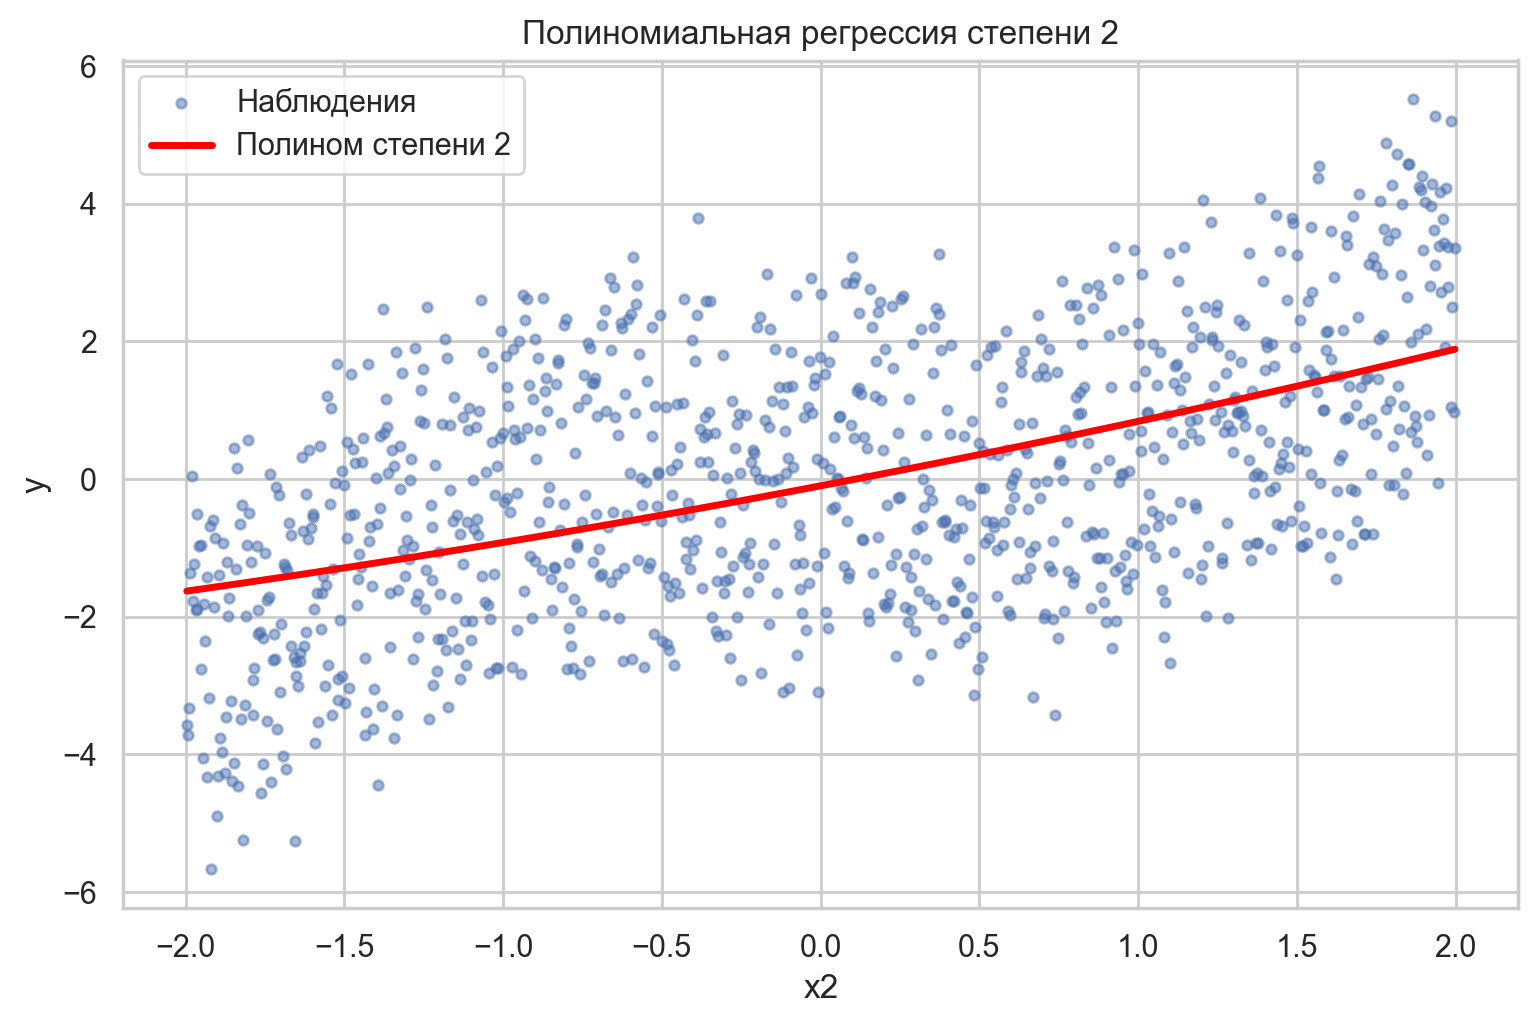

In [16]:
def plot_polynomial(ax, model, degree):
    """Наблюдения и линия полиномиальной регрессии y по x2."""
    grid = pd.DataFrame({'x2': np.linspace(points['x2'].min(), points['x2'].max(), 300)})
    ax.scatter(points['x2'], points['y'], s=12, alpha=0.5, label='Наблюдения')
    ax.plot(grid['x2'], model.predict(grid), color='red', linewidth=2.5,
            label=f'Полином степени {degree}')
    ax.set(xlabel='x2', ylabel='y', title=f'Полиномиальная регрессия степени {degree}')
    ax.legend()


fig, ax = plt.subplots(figsize=(9, 5.5))
plot_polynomial(ax, model_2, 2)
plt.show()

Полином степени 2 не лучше прямой: R2 на тесте 0.193 против 0.200 у линейной модели, а линия на графике почти прямая. Парабола симметрична относительно своей вершины, а зависимость `y` от `x2` выглядит иначе: слева она уходит вниз, справа вверх. Такую форму даёт нечётная степень.

### 2.3. Другие степени полинома

Те же шаги повторены для степеней 1, 3, 10 и 25. Степень 1 — это линейная регрессия из части 1, она нужна для сравнения.

In [17]:
poly_models = {degree: fit_polynomial(degree) for degree in [1, 2, 3, 10, 25]}

poly_scores = pd.DataFrame(
    {degree: train_test_scores(model, train[['x2']], test[['x2']], train['y'], test['y'])
     for degree, model in poly_models.items()}
).T.rename_axis('Степень полинома')
poly_scores

,R2 train,R2 test,MAE train,MAE test
Степень полинома,,,,
1,0.270955,0.199958,1.405642,1.358305
2,0.272194,0.192595,1.404138,1.363938
3,0.333691,0.273466,1.354580,1.314823
10,0.338618,0.279749,1.342531,1.305612
25,0.358558,0.245441,1.317925,1.320854


In [18]:
degree_predictions = pd.DataFrame({'Actual': test['y']})
for degree, model in poly_models.items():
    degree_predictions[f'Степень {degree}'] = model.predict(test[['x2']])

degree_predictions.head(10)

,Actual,Степень 1,Степень 2,Степень 3,Степень 10,Степень 25
521,0.897102,-1.014775,-1.017902,-0.482389,-0.434840,-0.715498
737,1.517751,-1.327183,-1.277450,-1.127322,-1.328822,-0.973030
740,-1.115664,-0.830492,-0.858088,-0.261433,-0.207829,0.217392
660,0.897899,0.026153,-0.049789,-0.084469,-0.040042,0.365454
411,-4.131951,-1.651730,-1.531921,-2.256446,-2.178845,-2.168263
678,-3.041178,-1.331875,-1.281238,-1.140034,-1.345804,-0.969911
626,-0.312387,0.365710,0.300394,-0.074717,-0.209540,-0.659105
513,1.532252,1.099324,1.114704,0.714951,0.830981,0.788726
859,-3.766478,-1.208523,-1.180553,-0.837238,-0.918728,-1.212165
136,4.138962,1.469590,1.555676,1.856446,1.639677,1.141461


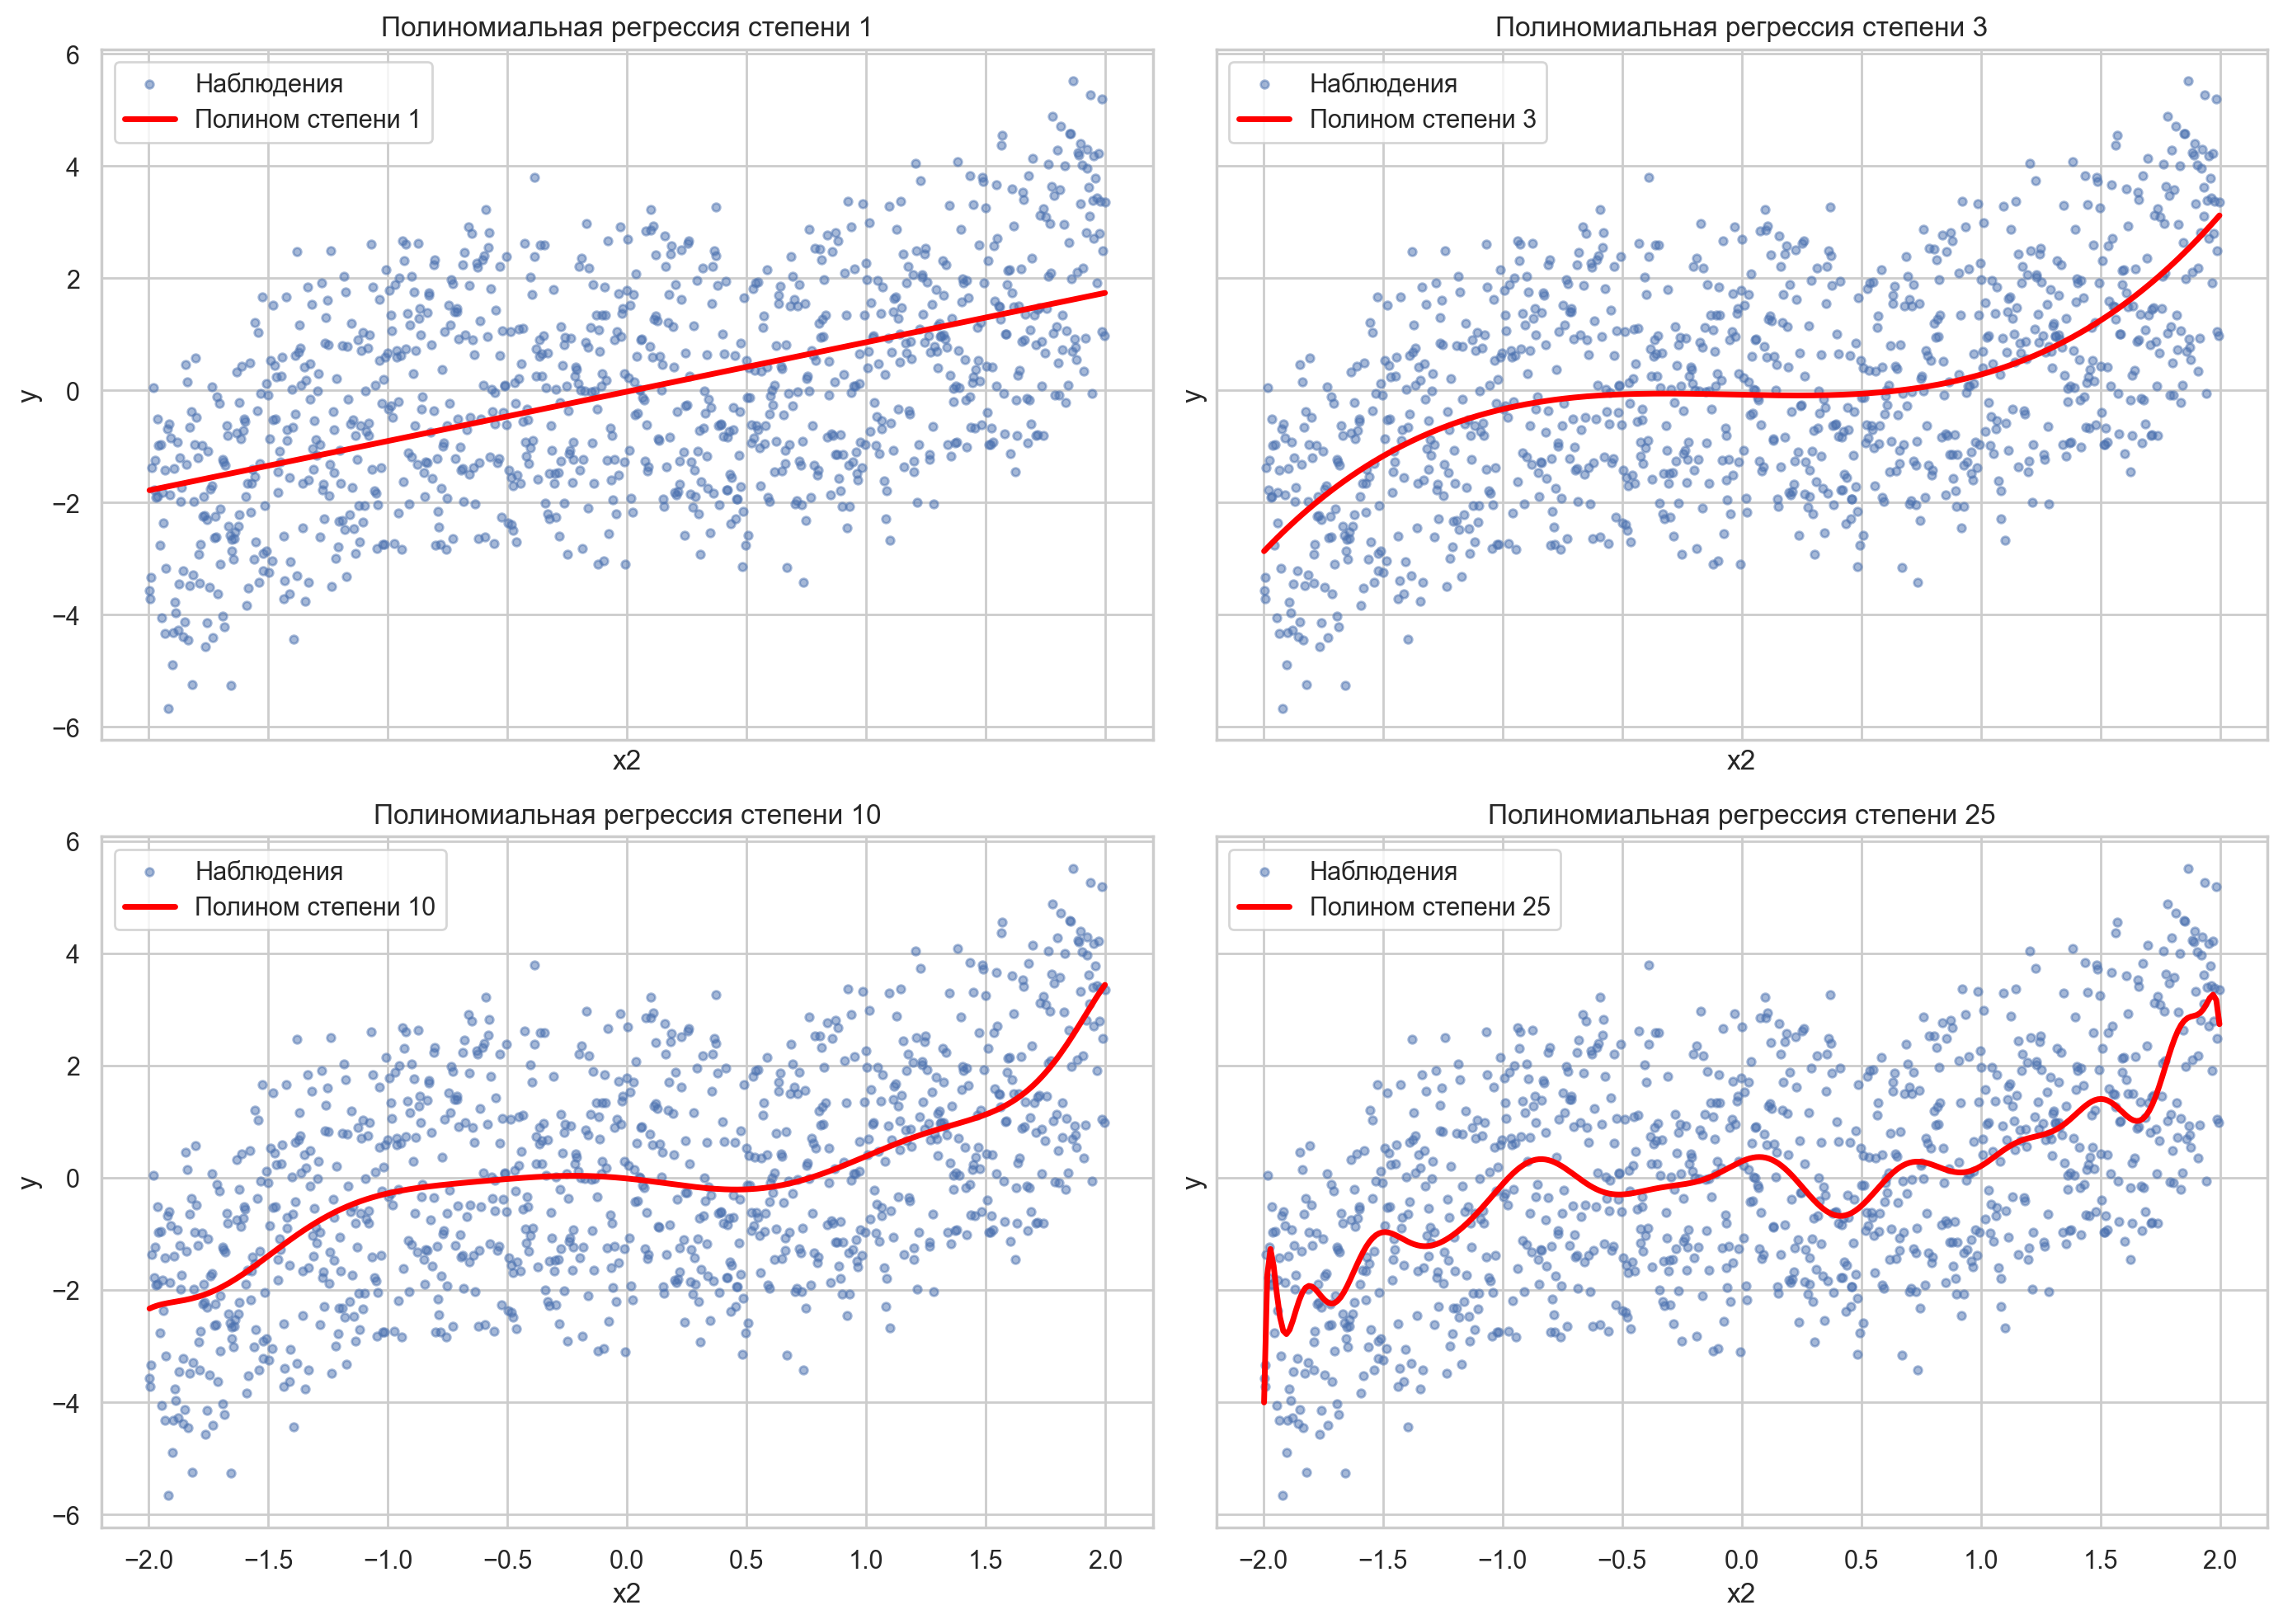

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

for ax, degree in zip(axes.flat, [1, 3, 10, 25]):
    plot_polynomial(ax, poly_models[degree], degree)

fig.tight_layout()
plt.show()

### 2.4. Выводы по части 2

**Какую степень использовать.** Оптимальная степень — 3. При переходе от степени 2 к степени 3 R2 на тесте вырос с 0.193 до 0.273, MAE на тесте упала с 1.364 до 1.315. Кривая на графике повторяет форму облака: плато в середине и быстрый рост у краёв.

**Если степень слишком низкая,** модель недообучается. Полиномы степеней 1 и 2 одинаково плохи и на обучающей, и на тестовой выборке (R2 около 0.27 и 0.20): им не хватает гибкости, чтобы повторить изгиб.

**Если степень слишком высокая,** модель переобучается. У полинома степени 25 лучший R2 на обучающей выборке (0.359), но на тесте он упал до 0.245 — хуже, чем у степени 3. На графике кривая колеблется, особенно у краёв отрезка: она подстраивается под шум в обучающих точках, а не под зависимость.

Степень 10 даёт на тесте R2 = 0.280, на 0.006 больше, чем степень 3. Это прирост в пределах случайного разброса, а коэффициентов у модели становится 10 вместо 3, поэтому усложнять модель не стоит.

Даже лучший полином объясняет только 27 % дисперсии `y` на тесте. Причина не в степени: `y` сильнее зависит от `x1`, а эта модель `x1` не использует.

## Часть 3. Регрессия различными методами

### 3.1. Загрузка данных

Набор данных `salary.csv`. Каждая строка — один сотрудник.

| Столбец | Что хранит |
|---|---|
| `age` | возраст, лет |
| `income` | годовой доход до текущей работы |
| `experience` | количество полных лет профессионального опыта |
| `score_test` | результат профессионального теста |
| `hours_worked` | среднее количество рабочих часов в неделю |
| `distance_to_work` | расстояние от дома до работы |
| `savings` | сумма сбережений на банковском счёте |
| `debt` | общий объём текущих долгов |
| `education` | уровень образования: `High School`, `Bachelor`, `Master`, `PhD` |
| `city` | город проживания |
| `job_type` | сфера деятельности |
| `marital_status` | семейное положение |
| `car` | наличие автомобиля |
| `remote_work` | работает ли сотрудник удалённо |
| `salary` | годовая зарплата |

In [20]:
salary = pd.read_csv(data_source('salary.csv'))
salary.head()

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,PhD,Chicago,Finance,Single,Yes,Yes,106233.833479
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,High School,Houston,Retail,Single,No,Yes,87205.291042
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,PhD,Los Angeles,Finance,Married,Yes,No,69369.283522
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,Bachelor,Los Angeles,IT,Married,Yes,No,76587.116955
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,Bachelor,Phoenix,IT,Married,No,No,71023.148842


In [21]:
salary.info()
print('Дубликатов:', salary.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1500 non-null   int64  
 1   income            1500 non-null   float64
 2   experience        1500 non-null   int64  
 3   score_test        1500 non-null   float64
 4   hours_worked      1500 non-null   int64  
 5   distance_to_work  1500 non-null   float64
 6   savings           1500 non-null   float64
 7   debt              1500 non-null   float64
 8   education         1500 non-null   object 
 9   city              1500 non-null   object 
 10  job_type          1500 non-null   object 
 11  marital_status    1500 non-null   object 
 12  car               1500 non-null   object 
 13  remote_work       1500 non-null   object 
 14  salary            1500 non-null   float64
dtypes: float64(6), int64(3), object(6)
memory usage: 175.9+ KB
Дубликатов: 0


В таблице 1500 строк и 15 столбцов, пропусков и дубликатов нет. Числовых столбцов 9, категориальных 6.

In [22]:
salary.describe().round(1)

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary
count,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0
mean,43.7,50493.6,19.5,74.6,49.0,10.2,19920.7,7656.7,98573.1
std,15.1,15354.5,11.5,9.9,17.1,10.0,13635.5,5481.4,111786.8
min,18.0,-826.4,0.0,41.6,20.0,0.0,408.5,4.4,28589.0
25%,31.0,40526.0,10.0,67.8,34.0,3.0,9418.7,3138.5,69582.7
50%,44.0,50784.7,19.0,74.7,49.0,7.1,17114.5,6786.7,80310.4
75%,56.0,61105.0,29.0,81.6,63.0,14.4,27766.2,11008.3,91637.1
max,69.0,98819.7,39.0,107.3,79.0,82.6,101890.6,27276.7,985625.1


- У `salary` среднее (98 573) заметно больше медианы (80 310), стандартное отклонение (111 787) больше среднего, а максимум 985 625 в десять раз превышает третий квартиль. В столбце есть аномально большие значения.
- У `income` минимум отрицательный (−826.4), а доход отрицательным быть не может.
- `distance_to_work`, `savings` и `debt` скошены вправо: максимум в несколько раз больше третьего квартиля.

### 3.2. Целевая переменная

Целевая переменная — `salary`, годовая зарплата на текущей работе. Столбец `income` похож по смыслу, но это доход до текущей работы: он известен заранее и остаётся признаком.

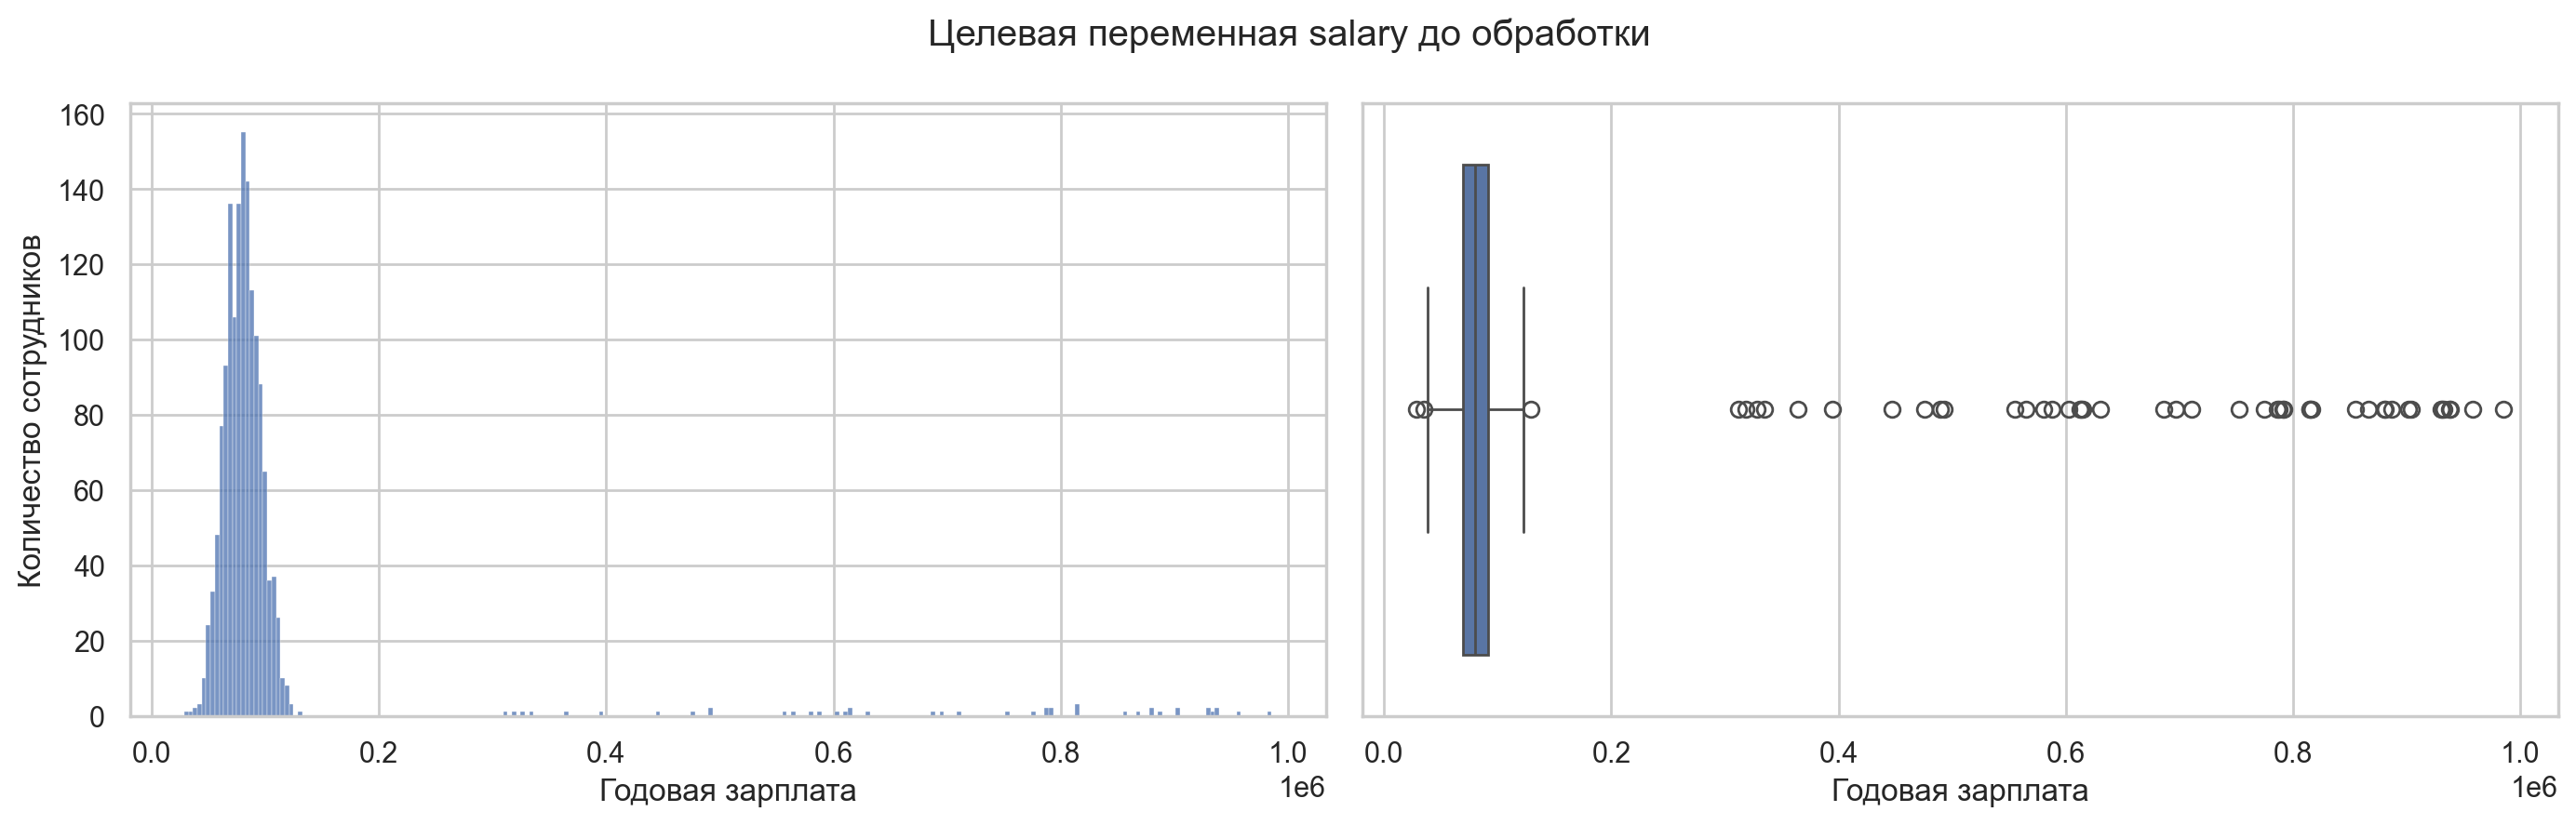

In [23]:
def plot_salary(values, title):
    """Гистограмма и диаграмма размаха зарплаты."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    sns.histplot(values, ax=axes[0])
    axes[0].set(xlabel='Годовая зарплата', ylabel='Количество сотрудников')
    sns.boxplot(x=values, ax=axes[1])
    axes[1].set(xlabel='Годовая зарплата')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_salary(salary['salary'], 'Целевая переменная salary до обработки')

Основная масса зарплат собрана в узкий пик около 80 000, а правее тянется редкий хвост до миллиона. На диаграмме размаха ящик сжат в полоску, справа от него десятки выбросов.

### 3.3. Обработка выбросов

Границы выбросов по правилу полутора межквартильных размахов:

In [24]:
q1, q3 = salary['salary'].quantile([0.25, 0.75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
below = salary.loc[salary['salary'] < lower, 'salary'].sort_values()
above = salary.loc[salary['salary'] > upper, 'salary'].sort_values()

print(f'Границы выбросов: {lower:.0f} и {upper:.0f}')
print(f'Ниже нижней границы: {len(below)} —', below.round().astype(int).tolist())
print(f'Выше верхней границы: {len(above)}')
print('  пять наименьших из них:', above.head().round().astype(int).tolist())
print('  наибольший:', round(above.max()))

Границы выбросов: 36501 и 124719
Ниже нижней границы: 2 — [28589, 34670]
Выше верхней границы: 46
  пять наименьших из них: [128998, 312155, 318447, 328029, 334908]
  наибольший: 985625


За границами лежат 48 значений, но они разные по природе:

- два значения снизу (28 589 и 34 670) и одно сверху (128 998) продолжают основное распределение и вышли за границы совсем немного;
- остальные 45 значений начинаются с 312 155, между ними и основной массой пусто.

Проверяю эти 45 строк отдельно — сравниваю зарплату с доходом до текущей работы:

In [25]:
anomalous = salary['salary'] > 200_000
salary_to_income = salary['salary'] / salary['income']

print('Аномальных зарплат:', anomalous.sum())
print(f'Медиана salary / income у аномальных строк: {salary_to_income[anomalous].median():.1f}')
print(f'Медиана salary / income у остальных строк: {salary_to_income[~anomalous].median():.1f}')

Аномальных зарплат: 45
Медиана salary / income у аномальных строк: 14.1
Медиана salary / income у остальных строк: 1.6


У обычных строк зарплата в 1.6 раза больше прежнего дохода, у аномальных — в 14 раз. Это ошибки в данных, а не высокооплачиваемые сотрудники: остальные признаки у этих строк обычные. Такие строки удаляю, иначе модель будет подстраиваться под них. Три граничных значения оставляю: это настоящие, хоть и редкие зарплаты.

Строка с отрицательным доходом:

In [26]:
salary.loc[salary['income'] <= 0, ['age', 'income', 'experience', 'salary']]

,age,income,experience,salary
593,24,-826.42124,35,59660.473066


Она одна, восстановить доход нечем, поэтому строка тоже удаляется.

Строк после обработки: 1454


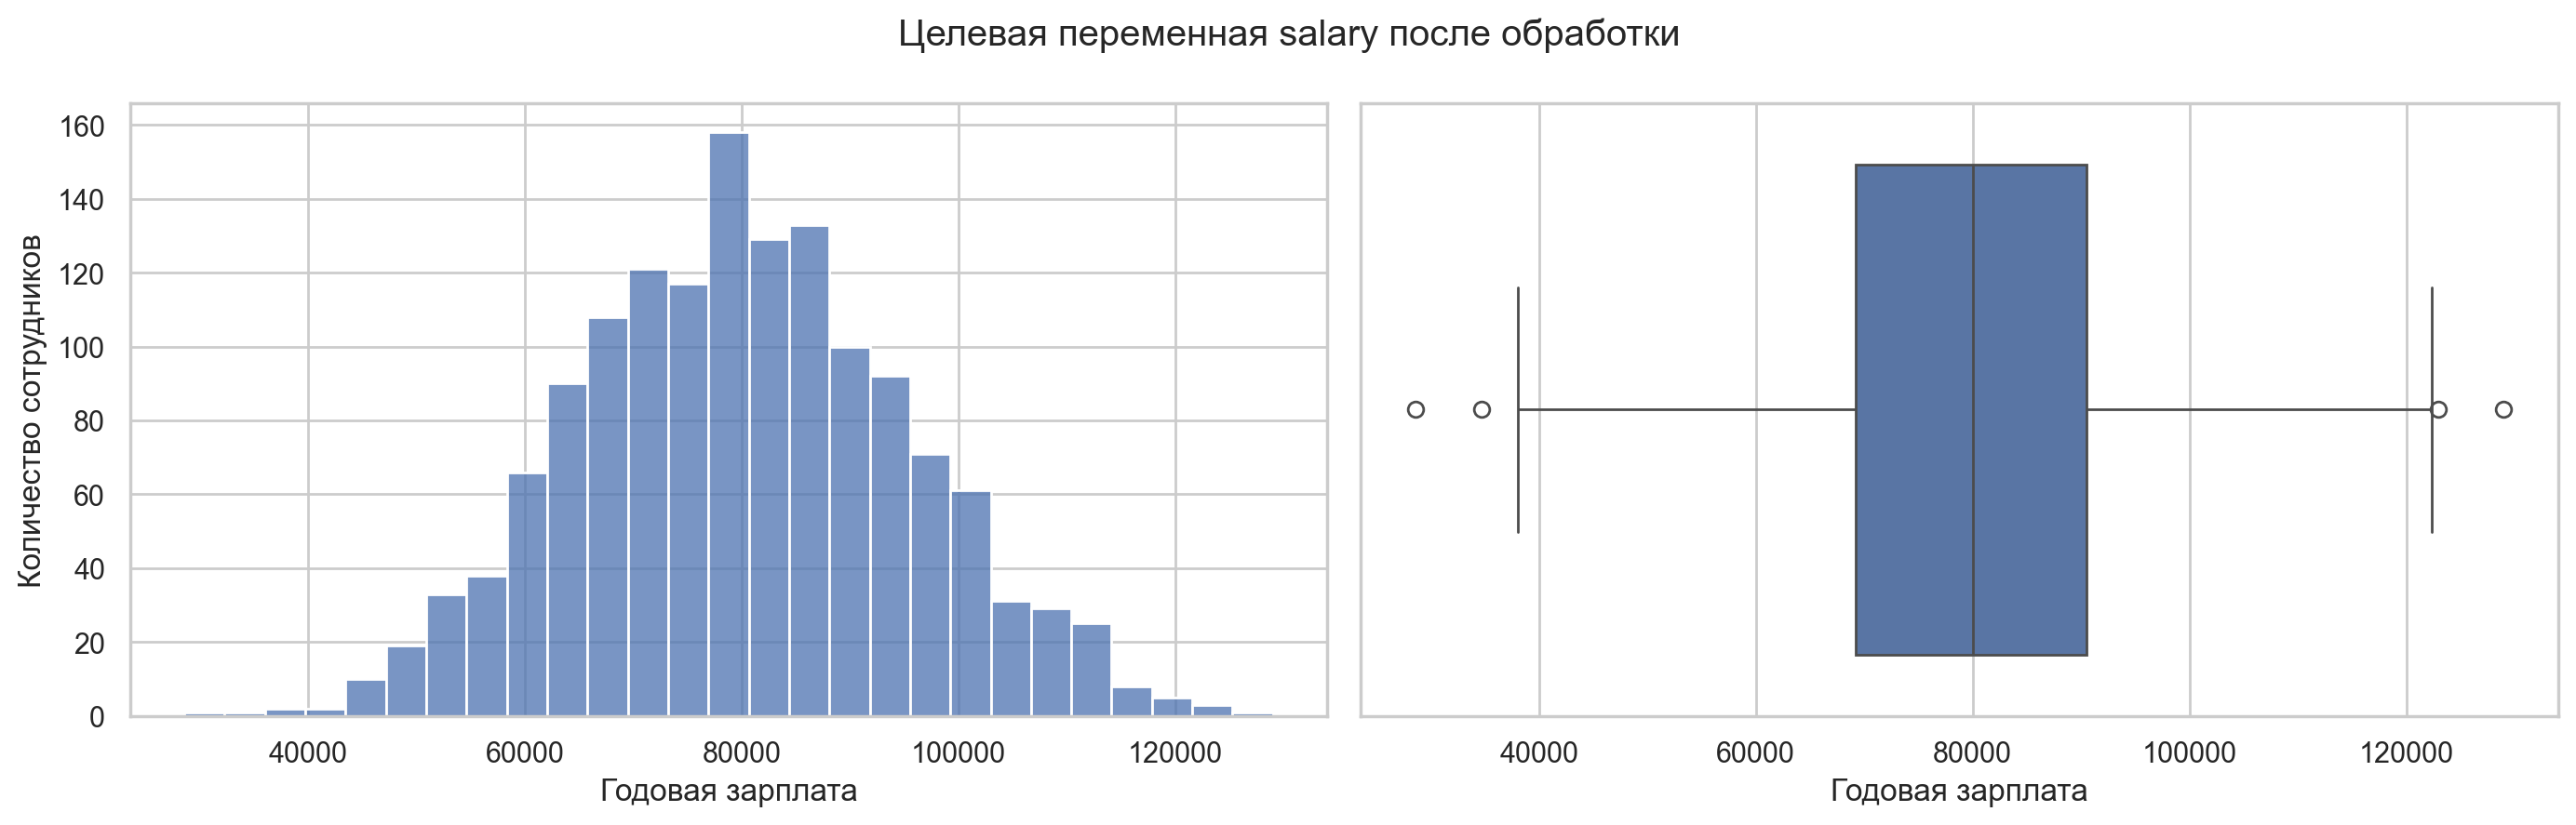

In [27]:
salary = salary[~anomalous & (salary['income'] > 0)].reset_index(drop=True)
print('Строк после обработки:', len(salary))

plot_salary(salary['salary'], 'Целевая переменная salary после обработки')

Осталось 1454 строки из 1500. Зарплата после обработки распределена симметрично и близка к нормальному распределению: от 28 589 до 128 998, среднее 80 099 почти совпадает с медианой 80 025, стандартное отклонение 15 295. На диаграмме размаха остались четыре точки у самых границ усов.

Выбросы в числовых признаках по тому же правилу:

In [28]:
NUMERIC = ['age', 'income', 'experience', 'score_test', 'hours_worked',
           'distance_to_work', 'savings', 'debt']

quartiles = salary[NUMERIC].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
is_outlier = (salary[NUMERIC] < quartiles.loc[0.25] - 1.5 * iqr) | \
             (salary[NUMERIC] > quartiles.loc[0.75] + 1.5 * iqr)

pd.DataFrame({'Выбросов': is_outlier.sum(),
              'Минимум': salary[NUMERIC].min().round(1),
              'Медиана': salary[NUMERIC].median().round(1),
              'Максимум': salary[NUMERIC].max().round(1)})

,Выбросов,Минимум,Медиана,Максимум
age,0,18.0,44.0,69.0
income,9,6477.1,50840.9,98819.7
experience,0,0.0,19.0,39.0
score_test,10,41.6,74.7,107.3
hours_worked,0,20.0,49.0,79.0
distance_to_work,64,0.0,7.1,82.6
savings,34,408.5,17125.1,101890.6
debt,14,4.4,6712.5,27276.7


Больше всего выбросов у `distance_to_work` (64), `savings` (34) и `debt` (14). Это не ошибки, а длинные правые хвосты: большинство живёт близко к работе и имеет небольшие сбережения, у немногих значения большие. У `income` и `score_test` выбросов около десяти, значения правдоподобные. Эти строки оставлены.

### 3.4. Кодирование признаков

Значения категориальных столбцов:

In [29]:
CATEGORICAL = ['education', 'city', 'job_type', 'marital_status', 'car', 'remote_work']

pd.Series({column: ', '.join(sorted(salary[column].unique())) for column in CATEGORICAL},
          name='Значения')

education                       Bachelor, High School, Master, PhD
city              Chicago, Houston, Los Angeles, New York, Phoenix
job_type                Education, Finance, Healthcare, IT, Retail
marital_status                           Divorced, Married, Single
car                                                        No, Yes
remote_work                                                No, Yes
Name: Значения, dtype: object

- `education` — порядковый признак: уровни образования идут по возрастанию. Он кодируется числами 0–3 через `OrdinalEncoder`, порядок уровней задан явно, иначе кодировщик расставил бы их по алфавиту.
- `city`, `job_type`, `marital_status` — номинальные признаки, порядка между значениями нет. Порядковое кодирование навязало бы модели ложное предположение, что один город «больше» другого, поэтому они кодируются прямым кодированием (`pd.get_dummies`).
- `car` и `remote_work` принимают два значения и тем же способом превращаются в один столбец 0/1.

Параметр `drop_first=True` убирает по одному столбцу у каждого признака. Без этого сумма фиктивных столбцов одного признака всегда равна единице, и вместе со свободным членом получается строгая линейная зависимость. Убранные значения становятся базовыми: Chicago, Education, Divorced, No.

In [30]:
EDUCATION_LEVELS = ['High School', 'Bachelor', 'Master', 'PhD']

encoded = salary.copy()
education_encoder = OrdinalEncoder(categories=[EDUCATION_LEVELS])
encoded[['education']] = education_encoder.fit_transform(encoded[['education']])
encoded = pd.get_dummies(encoded, columns=['city', 'job_type', 'marital_status',
                                           'car', 'remote_work'],
                         drop_first=True, dtype=int)

print('Столбцов после кодирования:', encoded.shape[1])
encoded.head(3).T.round(1)

Столбцов после кодирования: 22


,0,1,2
age,56.0,69.0,46.0
income,70201.2,51901.9,38605.4
experience,25.0,39.0,4.0
score_test,87.6,70.8,63.3
hours_worked,62.0,36.0,77.0
distance_to_work,3.7,7.1,5.1
savings,25987.3,22134.9,47106.1
debt,2556.8,725.2,12659.4
education,3.0,0.0,3.0
salary,106233.8,87205.3,69369.3


После кодирования в таблице 22 столбца: 21 признак и целевая переменная.

### 3.5. Матрица диаграмм рассеяния

Матрица построена по числовым признакам и зарплате после обработки выбросов. Показана нижняя половина: верхняя её зеркально повторяет.

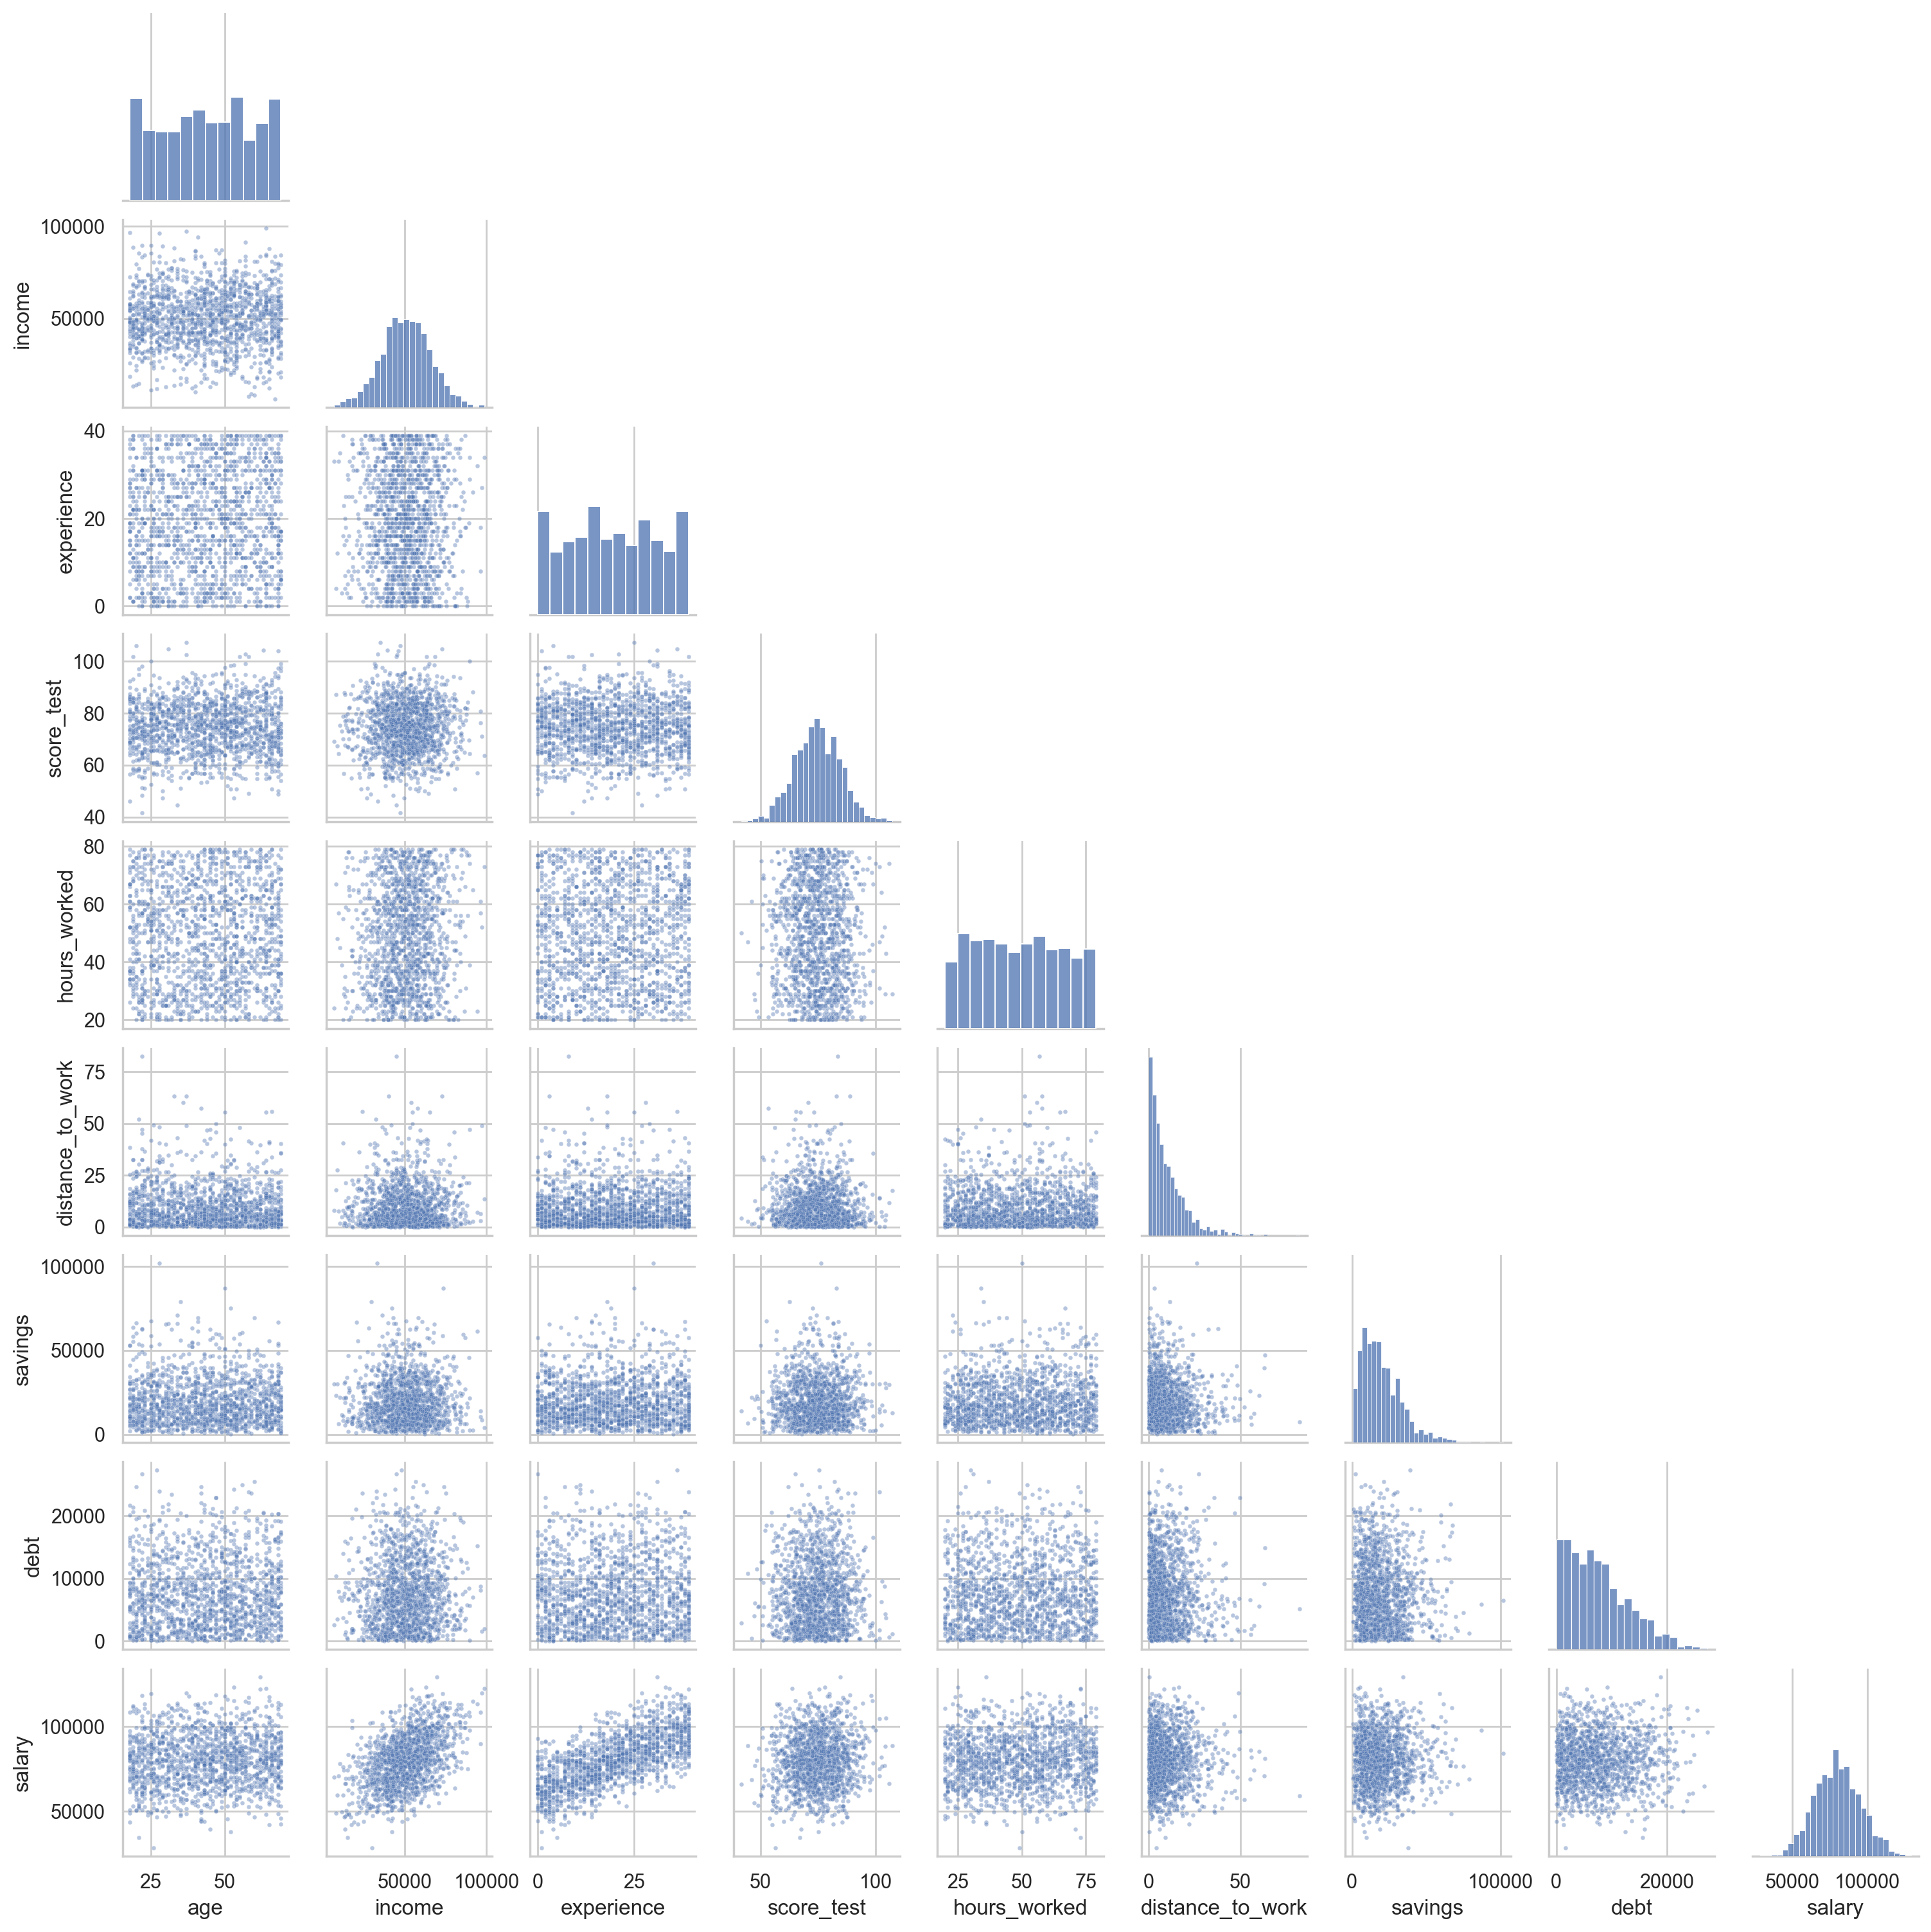

In [31]:
sns.pairplot(salary, vars=NUMERIC + ['salary'], corner=True, height=1.7,
             plot_kws={'s': 6, 'alpha': 0.4})
plt.show()

Нижняя строка — зависимость зарплаты от каждого признака:

- зарплата растёт вместе со стажем (`experience`) и прежним доходом (`income`), обе зависимости линейные;
- с остальными числовыми признаками зарплата образует круглые или вытянутые по горизонтали облака, связи не видно;
- признаки между собой не связаны: на остальных диаграммах облака точек не имеют направления.

### 3.6. Разделение на обучающую и тестовую выборки

In [32]:
X = encoded.drop(columns='salary')
y = encoded['salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                                    random_state=RANDOM_STATE)
print(f'Обучающая выборка: {X_train.shape}, тестовая: {X_test.shape}')

Обучающая выборка: (1090, 21), тестовая: (364, 21)


### 3.7. Масштабирование

Признаки измеряются в разных единицах: доход — десятки тысяч, образование — от 0 до 3. `StandardScaler` приводит каждый признак к среднему 0 и стандартному отклонению 1. После кодирования все признаки числовые, поэтому масштабируются все: тогда коэффициенты линейной регрессии можно сравнивать между собой, а в методе k-ближайших соседей признаки вносят равный вклад в расстояние.

Среднее и стандартное отклонение считаются только по обучающей выборке (`fit_transform`), а тестовая преобразуется уже готовыми параметрами (`transform`). Иначе сведения о тестовой выборке попали бы в обучение — это утечка данных.

In [33]:
scaler = StandardScaler().set_output(transform='pandas')
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# + 0 убирает отрицательный ноль после округления
pd.DataFrame({'Среднее до': X_train.mean(),
              'Ст. отклонение до': X_train.std(),
              'Среднее после': X_train_scaled.mean(),
              'Ст. отклонение после': X_train_scaled.std()}).round(2).head(9) + 0

,Среднее до,Ст. отклонение до,Среднее после,Ст. отклонение после
age,44.13,15.22,0.0,1.0
income,50578.00,15657.57,0.0,1.0
experience,19.46,11.46,0.0,1.0
score_test,74.69,9.81,0.0,1.0
hours_worked,49.17,17.11,0.0,1.0
distance_to_work,10.00,9.87,0.0,1.0
savings,20256.19,13806.63,0.0,1.0
debt,7578.59,5400.55,0.0,1.0
education,1.26,0.84,0.0,1.0


### 3.8. Линейная регрессия

Функция `evaluate` считает метрики на тестовой выборке: MSE, MAE, RMSE и R2 из части 1, а также MAPE — среднюю относительную ошибку в процентах. Для сравнения добавлен R2 на обучающей выборке: если он намного выше тестового, модель переобучена.

In [34]:
def evaluate(model):
    """Метрики модели на тестовой выборке и R2 на обучающей."""
    predicted = model.predict(X_test_scaled)
    return {**regression_metrics(y_test, predicted),
            'MAPE, %': 100 * mean_absolute_percentage_error(y_test, predicted),
            'R2 train': model.score(X_train_scaled, y_train)}


METRIC_DIGITS = {'MSE': 0, 'MAE': 0, 'RMSE': 0, 'R2': 3, 'MAPE, %': 2, 'R2 train': 3}

linear = LinearRegression().fit(X_train_scaled, y_train)
pd.DataFrame({'Линейная регрессия': evaluate(linear)}).T.round(METRIC_DIGITS)

,MSE,MAE,RMSE,R2,"MAPE, %",R2 train
Линейная регрессия,36814146.0,4885.0,6067.0,0.86,6.38,0.852


- R2 = 0.860: модель объясняет 86 % дисперсии зарплаты на тестовой выборке.
- MAE = 4885: в среднем прогноз отличается от фактической зарплаты на 4.9 тысячи.
- RMSE = 6067 при стандартном отклонении зарплаты в тестовой выборке 16 225 — ошибка в 2.7 раза меньше разброса самой зарплаты.
- MAPE = 6.38 %: в среднем модель ошибается на 6.4 % от зарплаты.
- R2 на обучающей выборке 0.852, почти как на тестовой. Переобучения нет.

### 3.9. Истинные и предсказанные значения

In [35]:
salary_predictions = pd.DataFrame({'Actual': y_test,
                                   'Линейная регрессия': linear.predict(X_test_scaled)})
salary_predictions.round(0).head(10)

,Actual,Линейная регрессия
497,77331.0,81596.0
1260,91689.0,84421.0
411,71439.0,75100.0
1179,50904.0,57388.0
1033,101832.0,107002.0
613,77224.0,82792.0
218,112397.0,106149.0
1181,84173.0,79887.0
1190,83897.0,86634.0
885,67282.0,68917.0


### 3.10. Коэффициенты и важность признаков

Признаки стандартизованы, поэтому коэффициент показывает, на сколько меняется зарплата при увеличении признака на одно стандартное отклонение. Чем больше коэффициент по модулю, тем важнее признак.

In [36]:
coefficients = pd.DataFrame({'Признак': X.columns, 'Коэффициент': linear.coef_})
coefficients = coefficients.sort_values('Коэффициент', key=abs, ascending=False)
print(f'Свободный член: {linear.intercept_:.1f}')
coefficients.round(1).reset_index(drop=True)

Свободный член: 79982.0


,Признак,Коэффициент
0,experience,10290.3
1,income,7526.0
2,education,5350.1
3,job_type_IT,1719.4
4,score_test,1190.4
5,job_type_Retail,-657.8
6,city_New York,611.1
7,job_type_Finance,579.8
8,hours_worked,538.2
9,car_Yes,-408.9


- Важнее всего стаж: +10 290 к зарплате на одно стандартное отклонение, то есть на 11.5 года опыта.
- Второй по важности — прежний доход (+7526), третий — уровень образования (+5350).
- Заметно меньше влияют работа в IT (+1719) и результат теста (+1190).
- Коэффициенты остальных 16 признаков меньше 700 по модулю. Возраст, сбережения, долги, расстояние до работы, город, семейное положение, автомобиль и удалённая работа на зарплату почти не влияют.

Свободный член 79 982 — это средняя зарплата в обучающей выборке: при стандартизованных признаках модель предсказывает её сотруднику со средними значениями всех признаков.

### 3.11. Фактическое и предсказанное значение

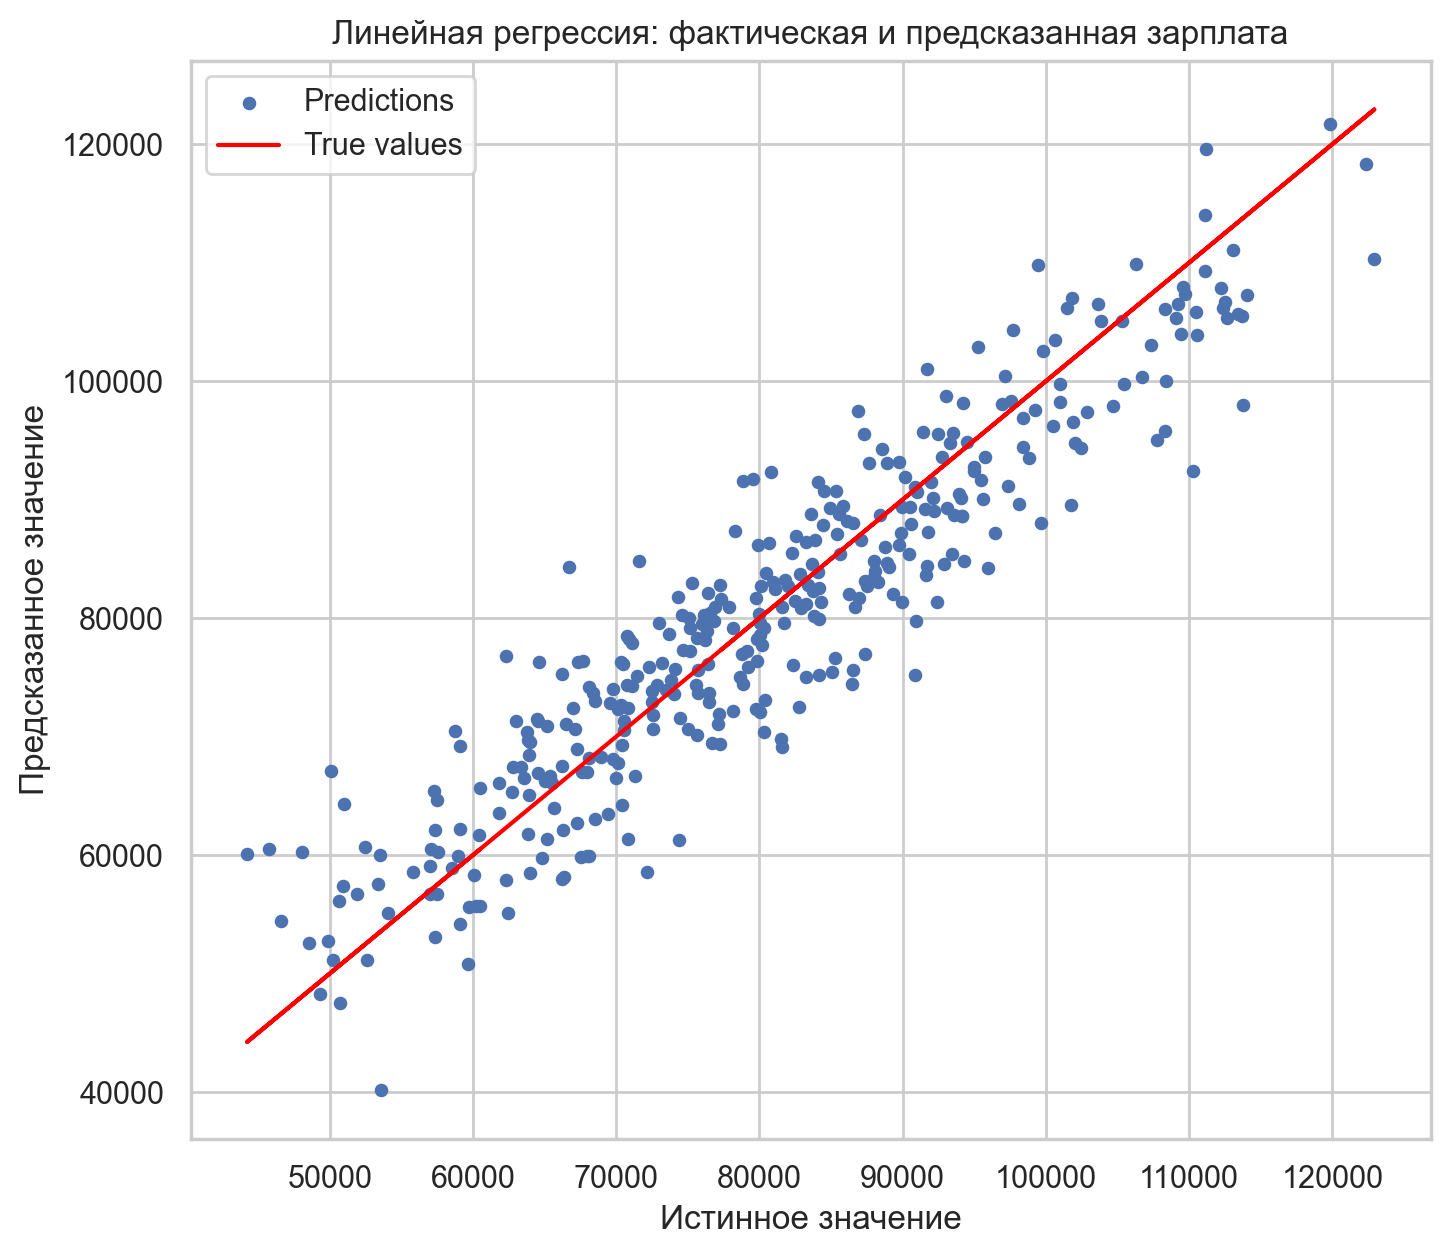

In [37]:
fig, ax = plt.subplots(figsize=(8, 7))
plot_predictions(ax, salary_predictions['Actual'], salary_predictions['Линейная регрессия'],
                 'Линейная регрессия: фактическая и предсказанная зарплата')
plt.show()

Точки лежат узкой полосой вдоль красной линии на всём диапазоне зарплат. Систематического сдвига нет: модель одинаково хорошо предсказывает и низкие, и высокие зарплаты.

### 3.12. Метод k-ближайших соседей и дерево решений

**Метод k-ближайших соседей** предсказывает зарплату как среднее по `k` самым похожим сотрудникам обучающей выборки. Число соседей оставлено по умолчанию: `k` = 5.

**Дерево решений** последовательно делит обучающую выборку по порогам признаков и в каждом листе предсказывает среднюю зарплату. Глубина дерева не ограничена — это тоже значение по умолчанию. `random_state` фиксирует выбор между равноценными разбиениями.

In [38]:
knn = KNeighborsRegressor().fit(X_train_scaled, y_train)
tree = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train_scaled, y_train)

### 3.13. Сравнение методов

In [39]:
models = {'Линейная регрессия': linear, 'k-ближайших соседей': knn, 'Дерево решений': tree}

results = {name: evaluate(model) for name, model in models.items()}
pd.DataFrame(results).T.round(METRIC_DIGITS)

,MSE,MAE,RMSE,R2,"MAPE, %",R2 train
Линейная регрессия,36814146.0,4885.0,6067.0,0.860,6.38,0.852
k-ближайших соседей,138973096.0,9429.0,11789.0,0.471,12.23,0.648
Дерево решений,102820083.0,8086.0,10140.0,0.608,10.40,1.000


In [40]:
for name, model in models.items():
    salary_predictions[name] = model.predict(X_test_scaled)

salary_predictions.round(0).head(10)

,Actual,Линейная регрессия,k-ближайших соседей,Дерево решений
497,77331.0,81596.0,78214.0,89080.0
1260,91689.0,84421.0,66931.0,78359.0
411,71439.0,75100.0,79245.0,73272.0
1179,50904.0,57388.0,71399.0,64631.0
1033,101832.0,107002.0,96637.0,106770.0
613,77224.0,82792.0,79730.0,80261.0
218,112397.0,106149.0,82045.0,105554.0
1181,84173.0,79887.0,80599.0,89836.0
1190,83897.0,86634.0,87376.0,88055.0
885,67282.0,68917.0,84602.0,28589.0


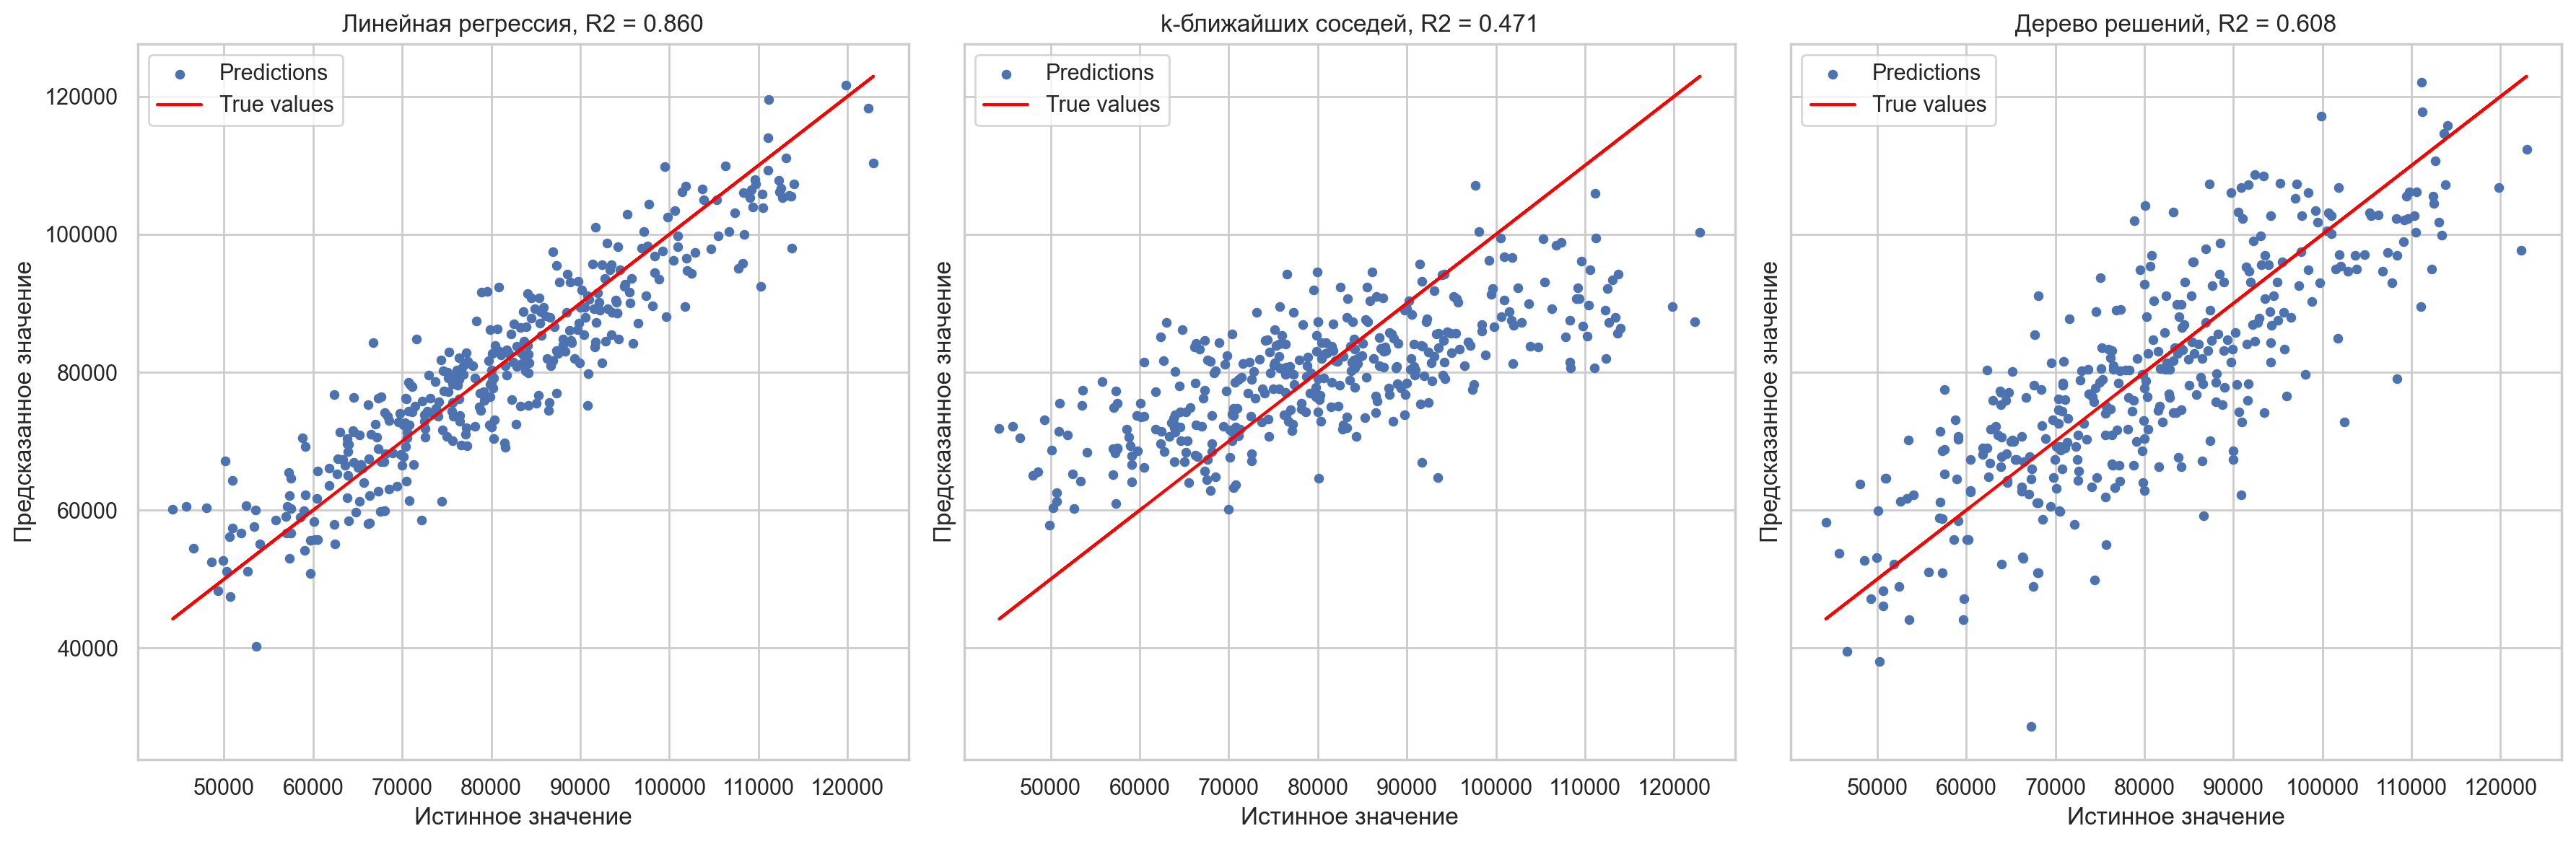

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, name in zip(axes, models):
    plot_predictions(ax, salary_predictions['Actual'], salary_predictions[name],
                     f"{name}, R2 = {results[name]['R2']:.3f}")

fig.tight_layout()
plt.show()

- **Линейная регрессия** — точки лежат вдоль красной линии узкой полосой.
- **k-ближайших соседей** — облако наклонено слабее линии. Предсказания стянуты к средней зарплате: они лежат в пределах от 57 805 до 107 120 при фактических зарплатах от 44 219 до 122 930. Низкие зарплаты модель завышает, высокие занижает. Расстояние считается по всем 21 признаку с равным весом, а на зарплату заметно влияют только три, поэтому «ближайшие» соседи часто похожи по неважным признакам.
- **Дерево решений** — облако идёт вдоль красной линии, но оно заметно шире, чем у линейной регрессии. Глубина не ограничена, и дерево делило выборку, пока не воспроизвело точно каждую обучающую зарплату: R2 на обучающей выборке равен 1.000, а на тестовой только 0.608. Дерево запомнило обучающие примеры вместе с шумом — это переобучение. Одна точка лежит далеко внизу: сотруднику с зарплатой 67 282 предсказано 28 589. Это самая низкая зарплата в наборе, сотрудник попал в лист с этим обучающим примером.

Все предсказания на одном графике. Сотрудники тестовой выборки упорядочены по фактической зарплате, чёрная линия — фактические значения.

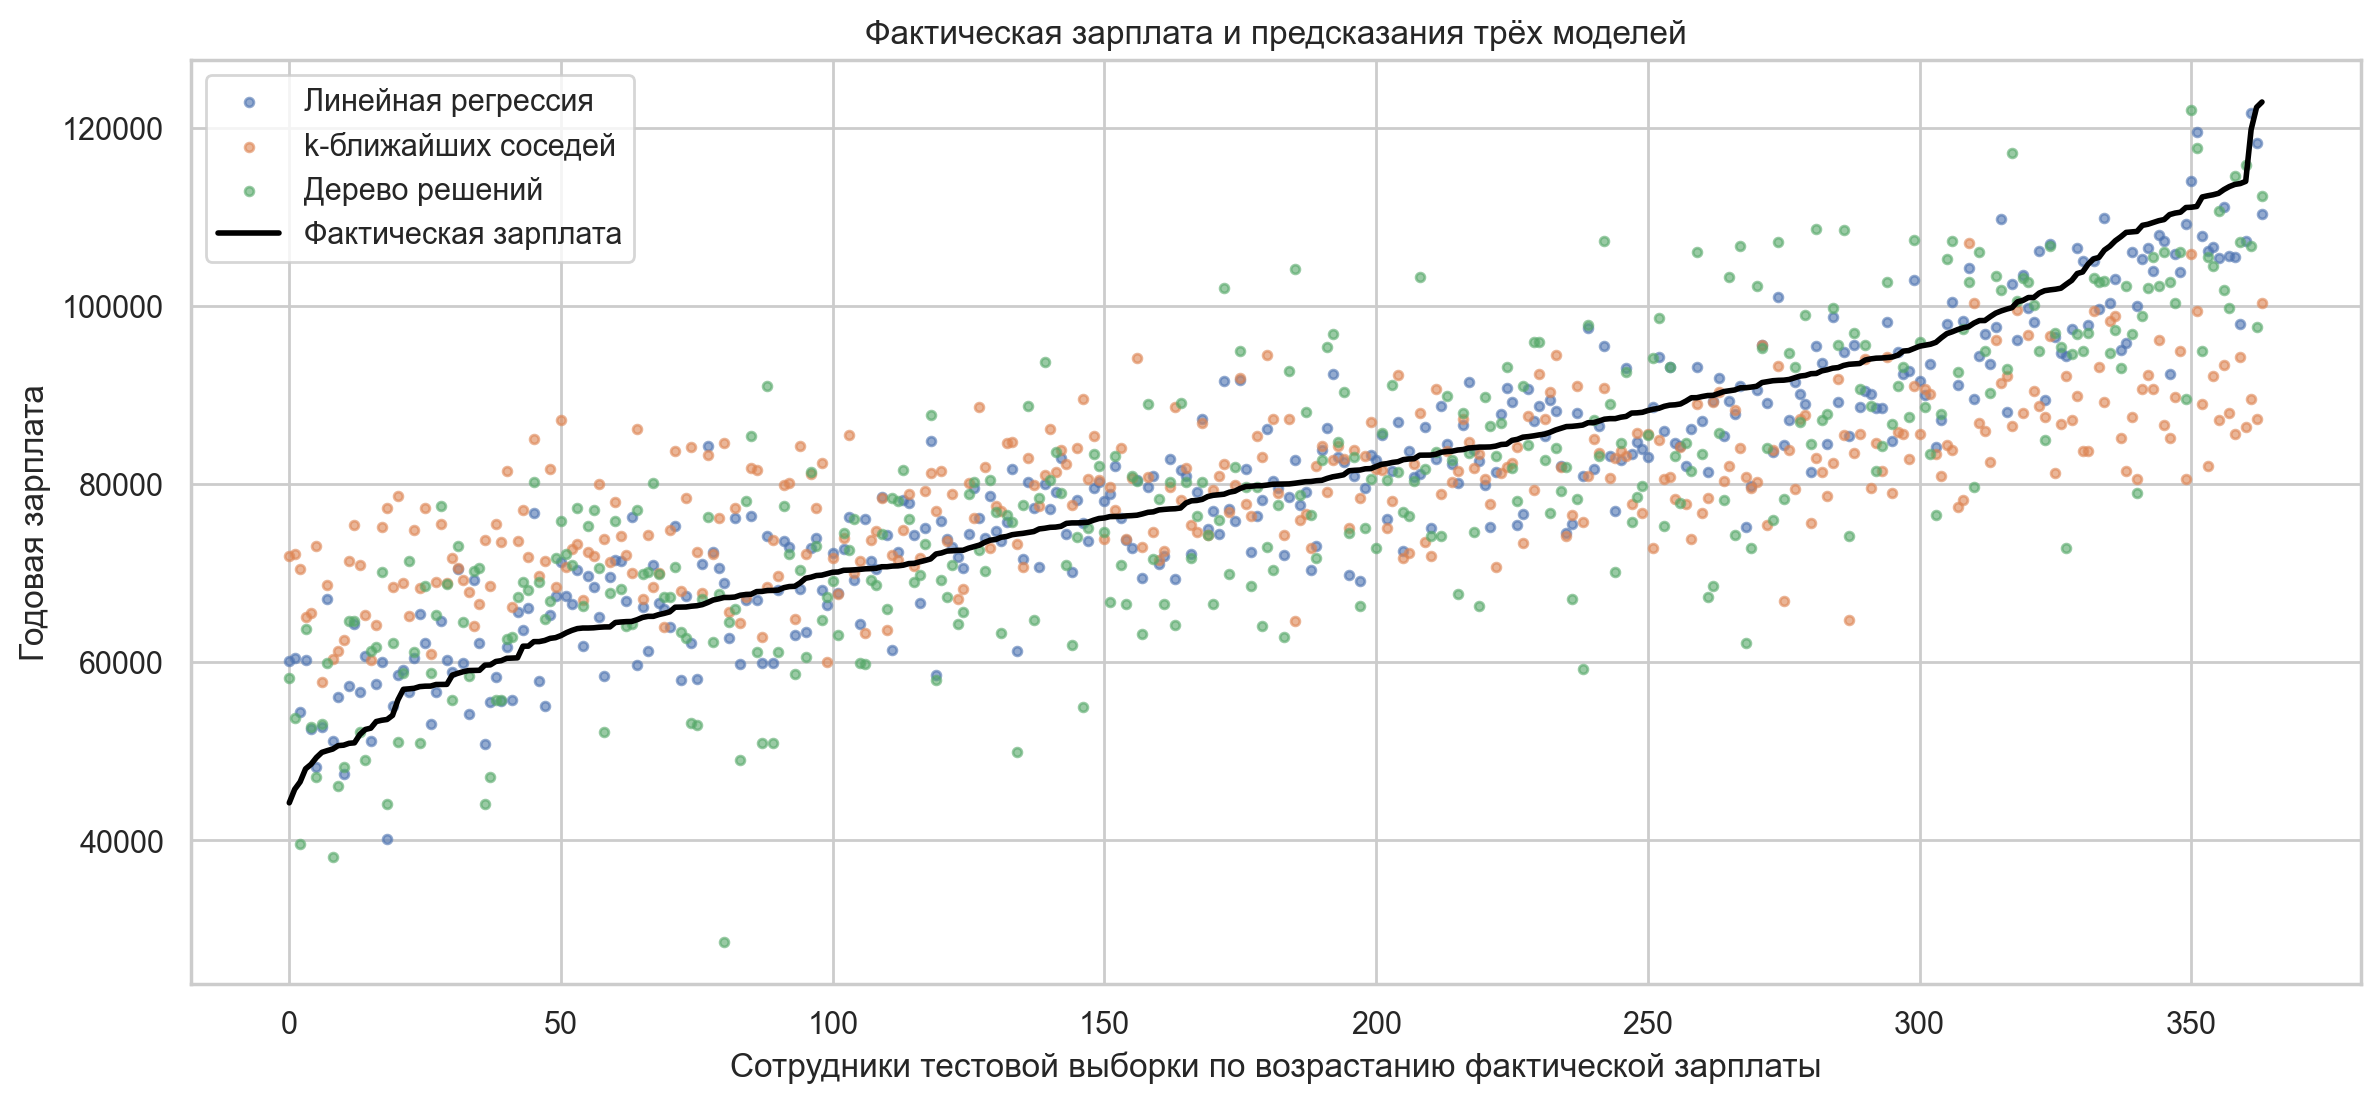

In [42]:
by_actual = salary_predictions.sort_values('Actual').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 6))
for name in models:
    ax.scatter(by_actual.index, by_actual[name], s=10, alpha=0.6, label=name)
ax.plot(by_actual.index, by_actual['Actual'], color='black', linewidth=2,
        label='Фактическая зарплата')
ax.set(xlabel='Сотрудники тестовой выборки по возрастанию фактической зарплаты',
       ylabel='Годовая зарплата',
       title='Фактическая зарплата и предсказания трёх моделей')
ax.legend()
plt.show()

Точки линейной регрессии держатся рядом с чёрной линией по всей её длине. Предсказания kNN образуют пологую полосу: слева она выше линии, справа ниже. Предсказания дерева следуют за линией, но разбросаны вокруг неё шире, чем у линейной регрессии.

### 3.14. Выводы по части 3

Набор данных `salary.csv` описывает 1500 сотрудников: возраст, стаж, прежний доход, образование, сферу деятельности и другие признаки. Целевая переменная — годовая зарплата `salary`.

Предобработка:

- удалены 45 строк с аномальной зарплатой от 312 тысяч до 986 тысяч — она в 14 раз больше прежнего дохода при обычных остальных признаках;
- удалена одна строка с отрицательным доходом. Осталось 1454 строки;
- `education` закодирован порядковыми числами 0–3, остальные категориальные признаки — прямым кодированием с удалением базового столбца. Получился 21 признак;
- выборка разделена на обучающую (1090 строк) и тестовую (364 строки), признаки стандартизованы по параметрам обучающей выборки.

Результаты на тестовой выборке:

| Модель | R2 | MAE | MAPE |
|---|---|---|---|
| Линейная регрессия | 0.860 | 4885 | 6.38 % |
| Дерево решений | 0.608 | 8086 | 10.40 % |
| k-ближайших соседей, k = 5 | 0.471 | 9429 | 12.23 % |

Целесообразнее использовать **линейную регрессию**. По средней ошибке она почти вдвое точнее kNN и в 1.7 раза точнее дерева, не переобучается (R2 на обучающей выборке 0.852, на тестовой 0.860) и легко интерпретируется: коэффициенты прямо показывают вклад каждого признака. Причина в самих данных: зарплата линейно зависит от стажа, прежнего дохода и уровня образования, и линейная модель описывает эту зависимость точно.

Дерево решений без ограничения глубины переобучается: R2 на обучающей выборке 1.000, на тестовой 0.608. Методу k-ближайших соседей мешают 18 признаков, которые на зарплату почти не влияют, но участвуют в расчёте расстояния наравне с важными.

Зарплату определяют три признака: стаж, прежний доход и уровень образования — у них наибольшие по модулю коэффициенты линейной регрессии.

## Выводы по работе

В работе изучены алгоритмы регрессии: парная линейная и полиномиальная регрессия на данных варианта 6 и три метода — линейная регрессия, k-ближайших соседей и дерево решений — на наборе данных о зарплатах.

- **Часть 1.** Связь `y` с `x1` линейная (корреляция 0.77), парная регрессия по `x1` даёт R2 = 0.56. Связь `y` с `x2` нелинейна, прямая по `x2` даёт R2 = 0.20, и в её ошибках видна волна.
- **Часть 2.** Для `x2` подходит полином степени 3: R2 на тесте вырос с 0.20 до 0.27. Степени 1 и 2 недообучаются, степень 25 переобучается — на обучающей выборке она лучшая, на тестовой хуже степени 3.
- **Часть 3.** После удаления 46 ошибочных строк и кодирования признаков лучшей оказалась линейная регрессия (R2 = 0.86, средняя ошибка 6.4 %). Дерево решений дало R2 = 0.61, метод k-ближайших соседей — 0.47.

Общий вывод: сложность модели должна соответствовать форме зависимости в данных. Линейную связь лучше всего описывает линейная модель, изогнутую — полином невысокой степени. Более гибкие модели на этих данных проигрывают: либо подстраиваются под шум, либо расходуют гибкость на неважные признаки.